# PPO Model Evaluation - Overcooked MARL

This notebook evaluates PPO models trained with `ppo_overcookedRLlib.py`.

Models can be loaded from:
- `models/` - Models copied after training
- `ray_results/` - Original Ray checkpoints


## 1. Imports and Setup


In [1]:
import os
import json
import sys
from pathlib import Path
from typing import Dict, List
from datetime import datetime
import numpy as np
import pandas as pd
import ray
from ray.rllib.algorithms.algorithm import Algorithm
from ray.rllib.models import ModelCatalog
from ray.tune.registry import register_env
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from collections import defaultdict

# Configure matplotlib to display plots in the notebook
%matplotlib inline

# Import from ppo_overcookedRLlib.py
from ppo_overcookedRLlib import ParallelEnvToMultiAgent, CNNPPOModel, ENVIRONMENT_CONFIG
from overcooked_marl_env import OvercookedMARL

# Visualization settings
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100

# Fix map path
_SCRIPT_DIR = os.getcwd()

# Check if overcooked_marl_env exists in current directory
if not os.path.exists(os.path.join(_SCRIPT_DIR, "overcooked_marl_env")):
    parent_dir = os.path.dirname(_SCRIPT_DIR)
    if os.path.exists(os.path.join(parent_dir, "overcooked_marl_env")):
        _SCRIPT_DIR = parent_dir

_MAP_PATH_ABS = os.path.join(_SCRIPT_DIR, "overcooked_marl_env", "map", "maps", "simple_map.txt")

# Ensure we always use simple_map.txt
if not os.path.exists(_MAP_PATH_ABS):
    alt_paths = [
        os.path.join(os.getcwd(), "overcooked_marl_env", "map", "maps", "simple_map.txt"),
        "overcooked_marl_env/map/maps/simple_map.txt",
    ]
    for alt_path in alt_paths:
        if os.path.exists(alt_path):
            _MAP_PATH_ABS = os.path.abspath(alt_path)
            break
    else:
        _MAP_PATH_ABS = "overcooked_marl_env/map/maps/simple_map.txt"

ENVIRONMENT_CONFIG['map_path'] = _MAP_PATH_ABS

# Local env_creator function
def env_creator(env_config=None):
    return OvercookedMARL(
        render_mode=ENVIRONMENT_CONFIG['render_mode'],
        map_path=ENVIRONMENT_CONFIG['map_path'], 
        num_fixed_agents=ENVIRONMENT_CONFIG['num_fixed_agents'],
        verbose=ENVIRONMENT_CONFIG['verbose']
    )

# Initialize Ray
ray.init(ignore_reinit_error=True)

# Register custom model
ModelCatalog.register_custom_model("cnn_ppo_model", CNNPPOModel)

# Register environment
env_name = "overcooked_marl_parallel"
register_env(env_name, lambda config: ParallelEnvToMultiAgent(env_creator()))


/home/thais/NewOvercookedEnv/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2025-11-23 22:39:48,575	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2025-11-23 22:39:51,405	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
/home/thais/NewOvercookedEnv/venv/lib/python3.12/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
2025

## 2. Discover Models (models/ and ray_results/)


In [2]:
def discover_models(models_dir="models"):
    """Discovers all trained models in the models/ folder."""
    models = []
    models_path = Path(models_dir).resolve()
    
    if not models_path.exists():
        print(f"Folder {models_path} not found!")
        return models
    
    for model_dir in models_path.iterdir():
        if not model_dir.is_dir() or not model_dir.name.startswith('PPO_Config_'):
            continue
        
        model_info_path = model_dir / "model_info.json"
        
        if not model_info_path.exists():
            print(f"WARNING: model_info.json not found in {model_dir.name}")
            continue
        
        try:
            with open(model_info_path, 'r') as f:
                model_info = json.load(f)
            
            checkpoint_path = str(model_dir.resolve())
            
            config_name = model_info.get('config_name', model_dir.name)
            training_reward = model_info.get('avg_reward', 0.0)
            params = model_info.get('params', {})
            training_config = model_info.get('training_config', {})
            
            models.append({
                'checkpoint_path': checkpoint_path,
                'model_dir': str(model_dir.resolve()),
                'config_name': config_name,
                'model_name': model_dir.name,
                'training_reward': float(training_reward),
                'params': params,
                'training_config': training_config,
                'model_info': model_info,
                'source': 'models'
            })
            
        except Exception as e:
            print(f"Error reading model_info.json from {model_dir.name}: {e}")
            continue
    
    models.sort(key=lambda x: x.get('training_reward', 0.0), reverse=True)
    return models

def discover_ray_checkpoints(ray_results_dir="ray_results", verbose=False):
    """Discovers checkpoints directly from ray_results/. Suporta nova estrutura com timestamp e parâmetros."""
    import csv
    import os
    
    models = []
    ray_results_path = Path(ray_results_dir).resolve()
    
    if not ray_results_path.exists():
        if verbose:
            print(f"Folder {ray_results_path} not found!")
        return models
    
    if verbose:
        print(f"Searching in: {ray_results_path}")
    
    # Buscar em todos os diretórios PPO_Marl_* (pode ser timestamp ou config antigo)
    timestamp_dirs = [d for d in ray_results_path.iterdir() if d.is_dir() and d.name.startswith('PPO_Marl_')]
    
    if verbose:
        print(f"Found {len(timestamp_dirs)} timestamp/config directories")
    
    for timestamp_dir in timestamp_dirs:
        if verbose:
            print(f"  Checking: {timestamp_dir.name}")
        
        # Buscar em subdiretórios (estrutura nova: PPO_Marl_Timestamp/PPO_Marl_lr.../)
        # ou diretamente (estrutura antiga: PPO_Marl_Config_XX/)
        exp_dirs = [d for d in timestamp_dir.iterdir() if d.is_dir()]
        
        if verbose:
            print(f"    Found {len(exp_dirs)} subdirectories")
        
        for exp_dir in exp_dirs:
            # Se for estrutura nova (diretório de parâmetros com prefixo PPO_Marl_), buscar diretamente
            # Se for estrutura antiga (PPO_Marl_Config_XX), processar diretamente
            if exp_dir.name.startswith('PPO_Marl_Config_'):
                # Estrutura antiga: processar diretamente
                process_exp_dir = exp_dir
                parent_dir = timestamp_dir
                config_num = process_exp_dir.name.split('_')[-1]
                config_name = f"PPO_Config_{config_num:0>2}"
                if verbose:
                    print(f"      Processing old structure: {exp_dir.name}")
            elif exp_dir.name.startswith('PPO_Marl_'):
                # Estrutura nova: diretório de parâmetros (PPO_Marl_lr0.001_...)
                # Trials estão diretamente dentro deste diretório (ou em subdiretórios)
                process_exp_dir = exp_dir
                parent_dir = exp_dir
                # Gerar config_name removendo o prefixo PPO_Marl_ para ter um nome mais limpo
                params_part = exp_dir.name.replace('PPO_Marl_', '')
                config_name = f"PPO_Config_{params_part}"
                if verbose:
                    print(f"      Processing new structure: {exp_dir.name}")
            else:
                # Ignorar outros diretórios
                if verbose:
                    print(f"      Skipping: {exp_dir.name} (doesn't match expected pattern)")
                continue
            
            # Função auxiliar para buscar trial directory recursivamente
            def find_trial_directory(base_dir):
                """Busca recursivamente por diretório de trial."""
                # Primeiro: buscar diretórios com padrão conhecido
                for d in base_dir.iterdir():
                    if d.is_dir() and d.name.startswith('PPO_overcooked_marl_parallel_'):
                        return d
                
                # Segundo: buscar qualquer subdiretório que contenha arquivos de trial
                for d in base_dir.iterdir():
                    if d.is_dir():
                        if (d / "progress.csv").exists() or (d / "params.json").exists() or (d / "result.json").exists():
                            return d
                        # Buscar recursivamente em subdiretórios (até 2 níveis)
                        for subd in d.iterdir():
                            if subd.is_dir() and subd.name.startswith('PPO_overcooked_marl_parallel_'):
                                return subd
                            if subd.is_dir() and ((subd / "progress.csv").exists() or (subd / "params.json").exists()):
                                return subd
                
                # Terceiro: verificar se os arquivos estão diretamente no base_dir
                if (base_dir / "progress.csv").exists() or (base_dir / "params.json").exists():
                    return base_dir
                
                return None
            
            # Buscar diretório do trial
            trial_dir = find_trial_directory(process_exp_dir)
            
            if not trial_dir:
                if verbose:
                    print(f"        No trial directory found in {process_exp_dir.name}")
                continue
            
            if verbose:
                print(f"        Found trial directory: {trial_dir.name}")
            
            # Buscar checkpoints (pode estar no trial_dir ou em subdiretórios)
            checkpoint_dirs = []
            
            # Buscar diretamente no trial_dir
            if trial_dir.exists():
                checkpoint_dirs = [d for d in trial_dir.iterdir() if d.is_dir() and d.name.startswith('checkpoint_')]
            
            # Se não encontrou, buscar recursivamente
            if not checkpoint_dirs:
                for root, dirs, files in os.walk(trial_dir):
                    for d in dirs:
                        if d.startswith('checkpoint_'):
                            checkpoint_path = Path(root) / d
                            if checkpoint_path.exists():
                                checkpoint_dirs.append(checkpoint_path)
                                if verbose:
                                    print(f"          Found checkpoint recursively: {checkpoint_path.relative_to(process_exp_dir)}")
            
            if verbose:
                print(f"          Found {len(checkpoint_dirs)} checkpoint directories")
            
            if not checkpoint_dirs:
                if verbose:
                    print(f"          No checkpoint directories found")
                continue
            
            # Sort and get the latest checkpoint
            checkpoint_dirs.sort(key=lambda x: int(x.name.split('_')[-1]) if x.name.split('_')[-1].isdigit() else 0, reverse=True)
            latest_checkpoint_dir = checkpoint_dirs[0]
            checkpoint_path = str(latest_checkpoint_dir.resolve())
            
            # Check if rllib_checkpoint.json exists
            if not (latest_checkpoint_dir / "rllib_checkpoint.json").exists():
                if verbose:
                    print(f"          rllib_checkpoint.json not found in {latest_checkpoint_dir.name}")
                continue
            
            # Extract average reward from progress.csv
            training_reward = 0.0
            progress_csv = trial_dir / "progress.csv"
            if progress_csv.exists():
                try:
                    with open(progress_csv, 'r') as f:
                        reader = csv.DictReader(f)
                        rows = list(reader)
                        if rows:
                            # Get the last value of episode_reward_mean
                            last_row = rows[-1]
                            reward_key = 'env_runners/episode_reward_mean'
                            if reward_key in last_row and last_row[reward_key]:
                                training_reward = float(last_row[reward_key])
                except Exception as e:
                    if verbose:
                        print(f"          Error reading progress.csv: {e}")
            
            # Extract hyperparameters from params.json ou model_info.json
            params = {}
            training_config = {}
            
            # Tentar ler model_info.json primeiro (nova estrutura)
            model_info_path = parent_dir / "model_info.json"
            if model_info_path.exists():
                try:
                    with open(model_info_path, 'r') as f:
                        model_info = json.load(f)
                        params = model_info.get('params', {})
                        training_config = model_info.get('training_config', {})
                        # Garantir que num_episodes está em training_config
                        if 'num_episodes' not in training_config and 'num_episodes' in params:
                            training_config['num_episodes'] = params.get('num_episodes', 0)
                except Exception:
                    pass
            
            # Fallback: ler params.json do trial
            if not params or not training_config:
                params_json = trial_dir / "params.json"
                if params_json.exists():
                    try:
                        with open(params_json, 'r') as f:
                            params_data = json.load(f)
                            # Extract relevant parameters
                            training_config = {
                                'learning_rate': params_data.get('lr', 0.0),
                                'gamma': params_data.get('gamma', 0.0),
                                'entropy_coeff': params_data.get('entropy_coeff', 0.0),
                                'train_batch_size': params_data.get('train_batch_size', 0),
                                'sgd_minibatch_size': params_data.get('sgd_minibatch_size', 0),
                                'num_epochs': params_data.get('num_sgd_iter', params_data.get('num_epochs', 0)),
                                'num_episodes': 0,  # Não disponível em params.json
                            }
                            params = {
                                'learning_rate': params_data.get('lr', 0.0),
                                'gamma': params_data.get('gamma', 0.0),
                                'entropy_coeff': params_data.get('entropy_coeff', 0.0),
                                'seed': params_data.get('seed', 42),
                            }
                    except Exception:
                        pass
            
            # Para estrutura nova, usar nome do diretório de parâmetros como identificador
            if exp_dir.name.startswith('PPO_Marl_') and not exp_dir.name.startswith('PPO_Marl_Config_'):
                model_name = f"{exp_dir.name}_{latest_checkpoint_dir.name}"
            else:
                model_name = f"{process_exp_dir.name}_{latest_checkpoint_dir.name}"
            
            models.append({
                'checkpoint_path': checkpoint_path,
                'model_dir': str(trial_dir.resolve()),
                'config_name': config_name,
                'model_name': model_name,
                'training_reward': float(training_reward),
                'params': params,
                'training_config': training_config,
                'source': 'ray_results',
                'checkpoint_name': latest_checkpoint_dir.name,
                'experiment_dir': str(process_exp_dir.resolve())
            })
    
    models.sort(key=lambda x: x.get('training_reward', 0.0), reverse=True)
    return models

# Discover models from ray_results/
print("Discovering models...")
models = discover_ray_checkpoints(verbose=True)
print(f"\nFound {len(models)} models in ray_results/")
for i, model in enumerate(models, 1):
    print(f"  {i}. {model['config_name']} ({model['checkpoint_name']}): training_reward={model['training_reward']:.2f}")

print(f"\nTotal models available: {len(models)}")


Discovering models...
Searching in: /home/thais/NewOvercookedEnv/ray_results
Found 1 timestamp/config directories
  Checking: PPO_Marl_20251123_024017
    Found 162 subdirectories
      Processing new structure: PPO_Marl_lr0.001_gamma0.9_batch4000_mb128_epochs16_episodes400_entropy0.2_seed42
        Found trial directory: PPO_overcooked_marl_parallel_c9b6b_00000_0_2025-11-23_10-24-49
          Found 12 checkpoint directories
      Processing new structure: PPO_Marl_lr0.001_gamma0.995_batch4000_mb128_epochs4_episodes100_entropy0.25_seed42
        Found trial directory: PPO_overcooked_marl_parallel_82168_00000_0_2025-11-23_12-45-59
          Found 3 checkpoint directories
      Processing new structure: PPO_Marl_lr0.001_gamma0.9_batch4000_mb128_epochs4_episodes200_entropy0.15_seed42
        Found trial directory: PPO_overcooked_marl_parallel_470d6_00000_0_2025-11-23_08-48-07
          Found 6 checkpoint directories
      Processing new structure: PPO_Marl_lr0.001_gamma0.995_batch4000_mb1

## 3. Manual Environment Test


In [3]:
def test_environment_manually(num_steps=20):
    """Tests the environment manually with known actions."""
    env = ParallelEnvToMultiAgent(env_creator())
    obs_dict, infos = env.reset()
    
    total_reward = 0.0
    rewards_history = []
    
    test_actions = [
        {"agent_0": 0, "agent_1": 0},
        {"agent_0": 1, "agent_1": 1},
        {"agent_0": 2, "agent_1": 2},
        {"agent_0": 3, "agent_1": 3},
        {"agent_0": 4, "agent_1": 4},
    ]
    
    for step in range(num_steps):
        actions = test_actions[step % len(test_actions)]
        obs_dict, rewards, terminations, truncations, infos = env.step(actions)
        
        step_reward = sum(rewards.values())
        total_reward += step_reward
        rewards_history.append(step_reward)
        
        if terminations.get('__all__', False) or truncations.get('__all__', False):
            break
    
    env.close()
    return total_reward, rewards_history

# Execute manual test (uncomment to run)
# test_environment_manually(num_steps=20)


## 4. Loading and Evaluation Functions


In [4]:
def load_model_from_checkpoint(checkpoint_path: str) -> Algorithm:
    """Loads a PPO model from checkpoint."""
    from pathlib import Path
    
    checkpoint_dir = Path(checkpoint_path)
    
    if not checkpoint_dir.is_dir():
        raise ValueError(f"Checkpoint path must be a directory: {checkpoint_path}")
    
    rllib_checkpoint_file = checkpoint_dir / "rllib_checkpoint.json"
    if not rllib_checkpoint_file.exists():
        raise FileNotFoundError(f"rllib_checkpoint.json not found in {checkpoint_path}")
    
    try:
        algorithm = Algorithm.from_checkpoint(str(checkpoint_dir))
        
        if algorithm is None:
            raise RuntimeError("Failed to load algorithm from checkpoint")
        
        return algorithm
        
    except Exception as e:
        raise RuntimeError(f"Failed to load model: {e}")


In [5]:
def evaluate_model(checkpoint_path: str, num_episodes: int = 15, max_steps: int = 1200, verbose: bool = False) -> Dict:
    """
    Evaluates a PPO model in the environment.
    
    Args:
        checkpoint_path: Path to the model checkpoint
        num_episodes: Number of episodes for evaluation
        max_steps: Maximum number of steps per episode
        verbose: If True, prints debug information
    
    Returns:
        Dictionary with evaluation metrics
    """
    import torch
    
    algorithm = load_model_from_checkpoint(checkpoint_path)
    
    # Get policy
    shared_policy = None
    
    try:
        shared_policy = algorithm.get_policy("shared_policy")
    except Exception:
        try:
            if hasattr(algorithm, 'workers') and algorithm.workers:
                worker = algorithm.workers.local_worker()
                if hasattr(worker, 'get_policy'):
                    shared_policy = worker.get_policy("shared_policy")
                    if shared_policy is None:
                        policies = worker.get_policies()
                        if policies:
                            shared_policy = policies[list(policies.keys())[0]]
        except Exception:
            pass
    
    if shared_policy is None:
        raise RuntimeError("Could not get policy from algorithm.")
    
    env = ParallelEnvToMultiAgent(env_creator())
    
    # Metrics
    episode_rewards = []
    episode_rewards_per_agent = defaultdict(list)
    episode_lengths = []
    deliveries_per_episode = []
    action_counts = defaultdict(int)
    action_counts_per_agent = defaultdict(lambda: defaultdict(int))
    success_episodes = 0
    
    for episode in range(num_episodes):
        obs_dict, infos = env.reset()
        
        episode_reward = 0.0
        episode_reward_agents = {agent: 0.0 for agent in env.agents}
        episode_length = 0
        
        initial_delivered = 0
        if "agent_0" in infos and isinstance(infos["agent_0"], dict):
            initial_delivered = len(infos["agent_0"].get('delivered_recipes', []))
        
        for step in range(max_steps):
            actions = {}
            
            for agent_id in env.agents:
                try:
                    obs = obs_dict[agent_id]
                    
                    if not isinstance(obs, np.ndarray):
                        obs = np.array(obs)
                    
                    if obs.dtype == np.uint8:
                        obs_for_model = obs
                    elif obs.dtype == np.float32 or obs.dtype == np.float64:
                        if obs.max() <= 1.0:
                            obs_for_model = (obs * 255.0).astype(np.uint8)
                        else:
                            obs_for_model = np.clip(obs, 0, 255).astype(np.uint8)
                    else:
                        obs_for_model = obs.astype(np.uint8)
                    
                    action, state_out, info = shared_policy.compute_single_action(
                        obs=obs_for_model,
                        explore=True,
                    )
                    
                    if isinstance(action, (np.ndarray, list)):
                        action = int(action[0] if len(action) > 0 else action)
                    elif hasattr(action, 'item'):
                        action = int(action.item())
                    else:
                        action = int(action)
                    
                    actions[agent_id] = action
                    
                except Exception:
                    actions[agent_id] = env.action_space[agent_id].sample()
            
            obs_dict, rewards, terminations, truncations, infos = env.step(actions)
            
            total_step_reward = sum(rewards.values())
            episode_reward += total_step_reward
            
            for agent, reward in rewards.items():
                episode_reward_agents[agent] += reward
                action_counts_per_agent[agent][int(actions[agent])] += 1
            
            for agent, action in actions.items():
                action_counts[int(action)] += 1
            
            episode_length += 1
            
            if terminations.get('__all__', False) or truncations.get('__all__', False):
                break
        
        final_delivered = 0
        if "agent_0" in infos and isinstance(infos["agent_0"], dict):
            final_delivered = len(infos["agent_0"].get('delivered_recipes', []))
        
        episode_deliveries = final_delivered - initial_delivered
        
        episode_rewards.append(episode_reward)
        episode_lengths.append(episode_length)
        deliveries_per_episode.append(episode_deliveries)
        
        for agent, reward in episode_reward_agents.items():
            episode_rewards_per_agent[agent].append(reward)
        
        if episode_deliveries > 0:
            success_episodes += 1
    
    env.close()
    
    total_actions = sum(action_counts.values())
    action_distribution = {action: count / total_actions for action, count in action_counts.items()} if total_actions > 0 else {}
    
    action_probs = [count / total_actions for count in action_counts.values()] if total_actions > 0 else []
    action_entropy = -sum(p * np.log(p + 1e-10) for p in action_probs) if action_probs else 0.0
    
    action_distribution_per_agent = {}
    for agent, agent_actions in action_counts_per_agent.items():
        agent_total = sum(agent_actions.values())
        action_distribution_per_agent[agent] = {
            action: count / agent_total 
            for action, count in agent_actions.items()
        } if agent_total > 0 else {}
    
    return {
        'checkpoint_path': checkpoint_path,
        'eval_rewards': episode_rewards,
        'eval_rewards_per_agent': {agent: rewards for agent, rewards in episode_rewards_per_agent.items()},
        'eval_lengths': episode_lengths,
        'mean_reward': np.mean(episode_rewards),
        'std_reward': np.std(episode_rewards),
        'mean_length': np.mean(episode_lengths),
        'deliveries_per_episode': deliveries_per_episode,
        'mean_deliveries': np.mean(deliveries_per_episode),
        'success_rate': success_episodes / num_episodes,
        'action_distribution': action_distribution,
        'action_distribution_per_agent': action_distribution_per_agent,
        'action_entropy': action_entropy,
        'interaction_frequency': action_distribution.get(4, 0.0)
    }


## 5. Evaluate Models


In [6]:
# Evaluate all found models (ray_results/ and models/)
if len(models) == 0:
    print("No models found in ray_results/ or models/!")
else:
    evaluation_results = []
    
    for i, model in enumerate(tqdm(models, desc="Evaluating models")):
        checkpoint_path = model['checkpoint_path']
        
        if os.path.exists(checkpoint_path):
            result = evaluate_model(checkpoint_path, num_episodes=15, max_steps=1200, verbose=False)
            
            result.update({
                'config_name': model['config_name'],
                'model_dir': model['model_dir'],
                'model_name': model['model_name'],
                'training_reward': model['training_reward'],
                'params': model['params'],
                'training_config': model.get('training_config', {}),
                'source': model.get('source', 'models')
            })
            
            evaluation_results.append(result)
        else:
            print(f"ERROR: Checkpoint not found: {checkpoint_path}")
    
    print(f"Evaluation completed! {len(evaluation_results)} models evaluated.")


Evaluating models:   0%|          | 0/162 [00:00<?, ?it/s]/home/thais/NewOvercookedEnv/venv/lib/python3.12/site-packages/ray/rllib/algorithms/algorithm.py:526: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
`UnifiedLogger` will be removed in Ray 2.7.
  return UnifiedLogger(config, logdir, loggers=None)
/home/thais/NewOvercookedEnv/venv/lib/python3.12/site-packages/ray/tune/logger/unified.py:53: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
The `JsonLogger interface is deprecated in favor of the `ray.tune.json.JsonLoggerCallback` interface and will be removed in Ray 2.7.
  self._loggers.append(cls(self.config, self.logdir, self.trial))
/home/thais/NewOvercookedEnv/venv/lib/python3.12/site-packages/ray/tune/

Evaluation completed! 162 models evaluated.


## 6. Visualizations


Salvando gráficos em: analysis_output/20251123_230532


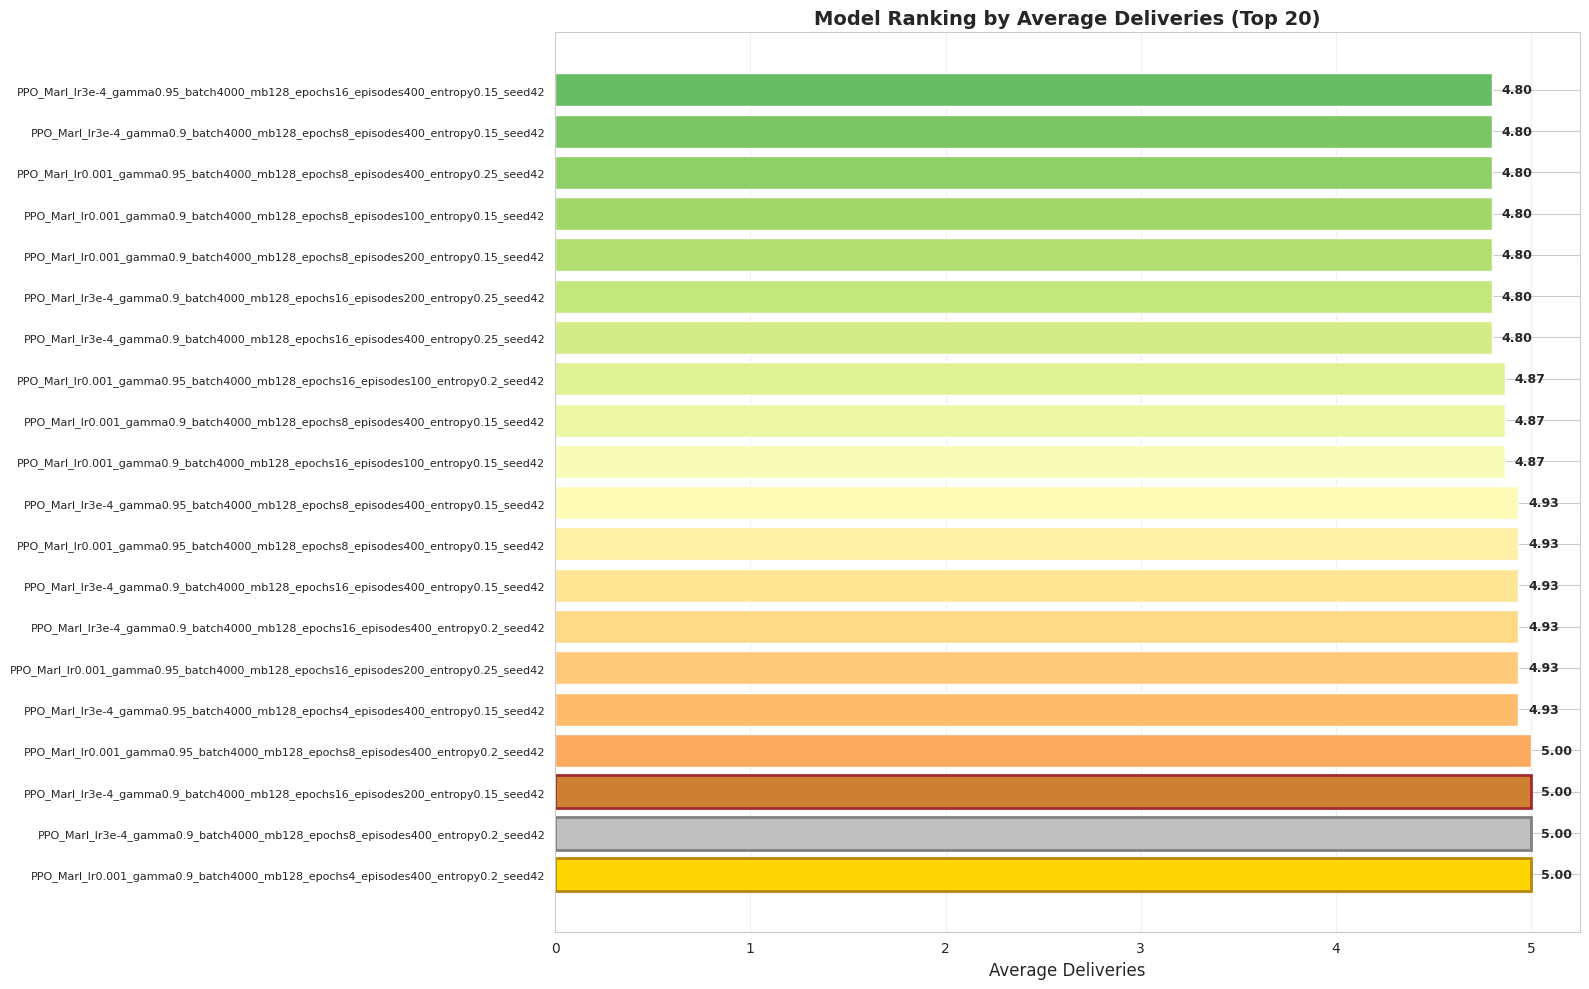

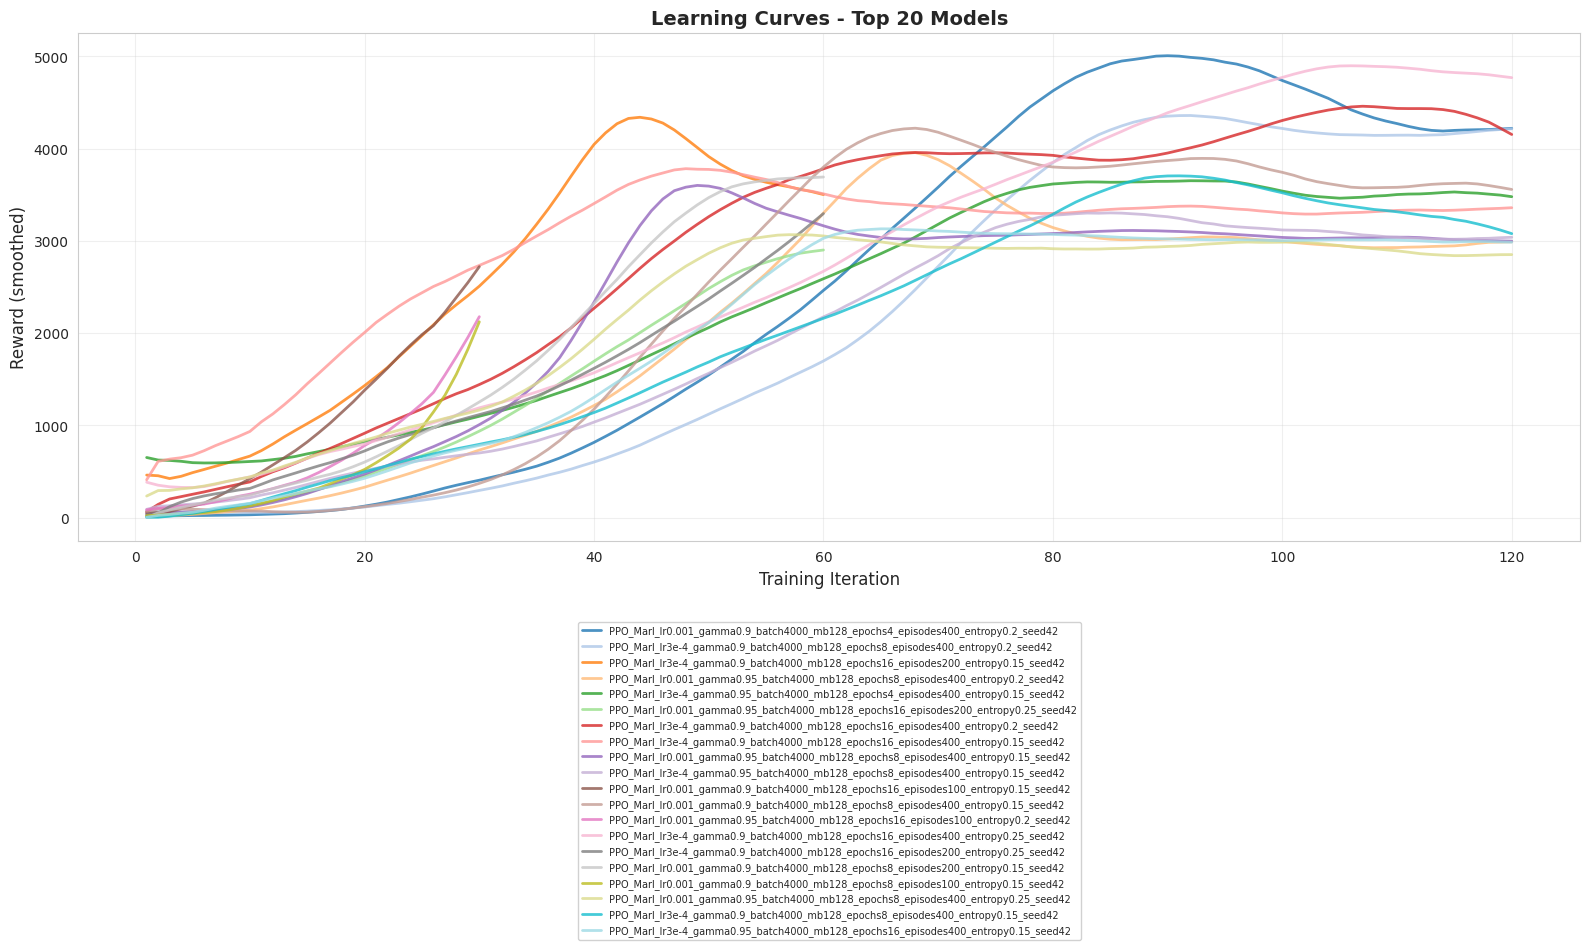

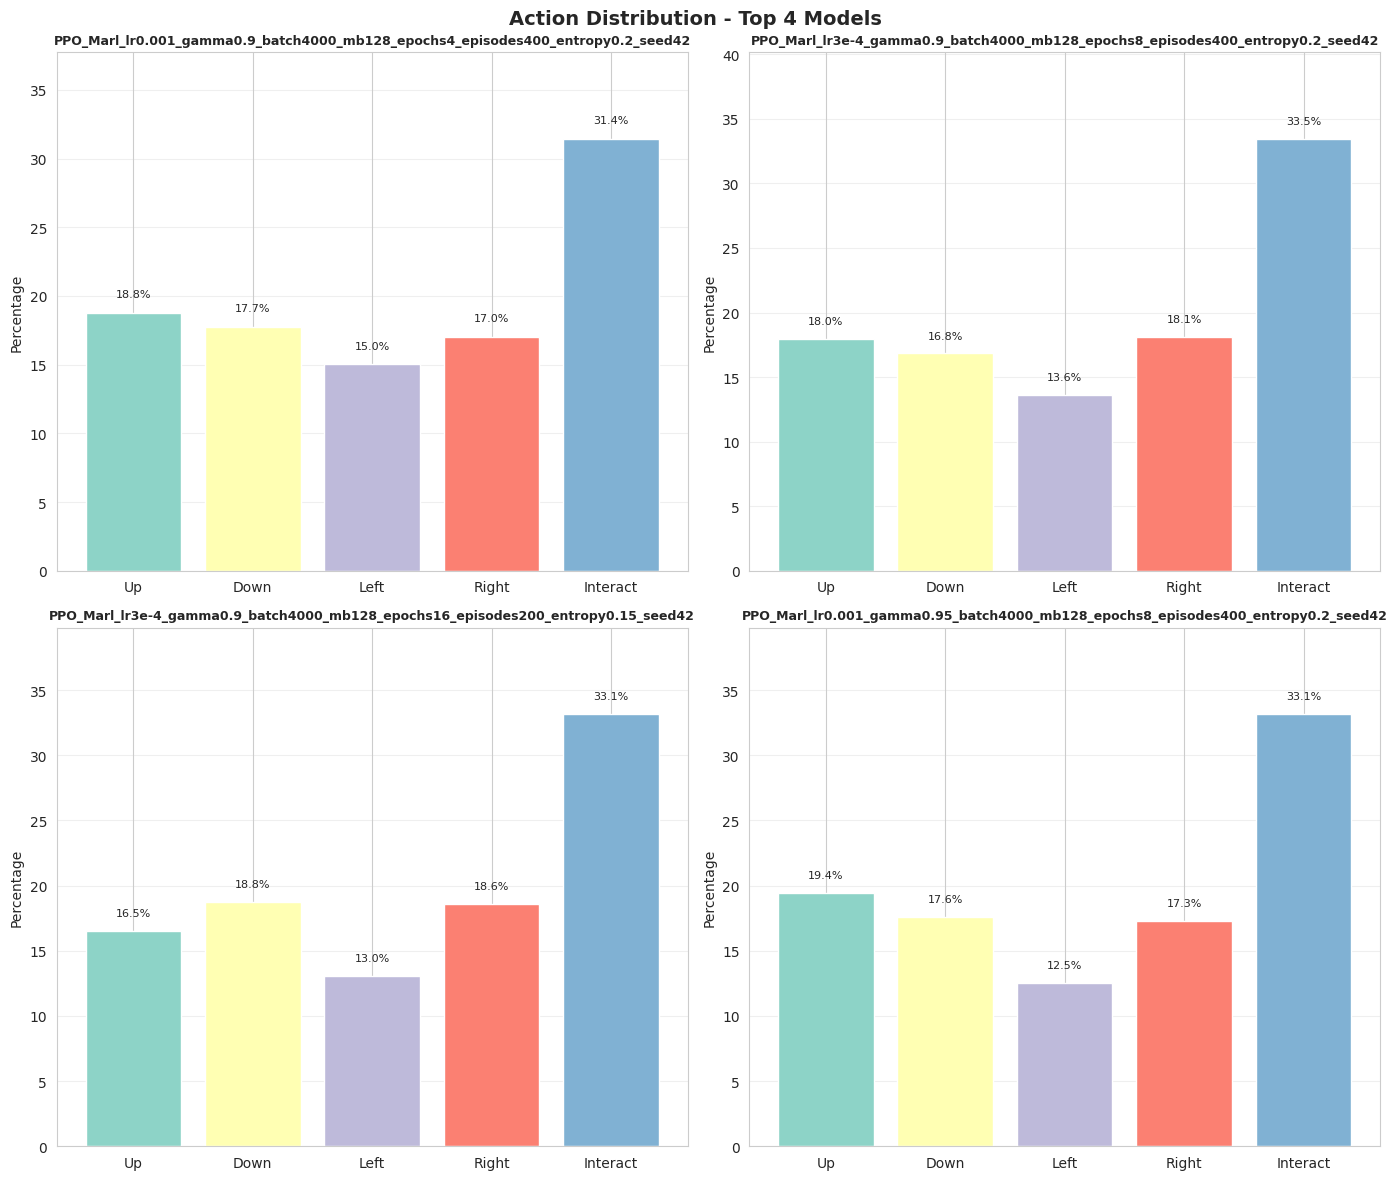

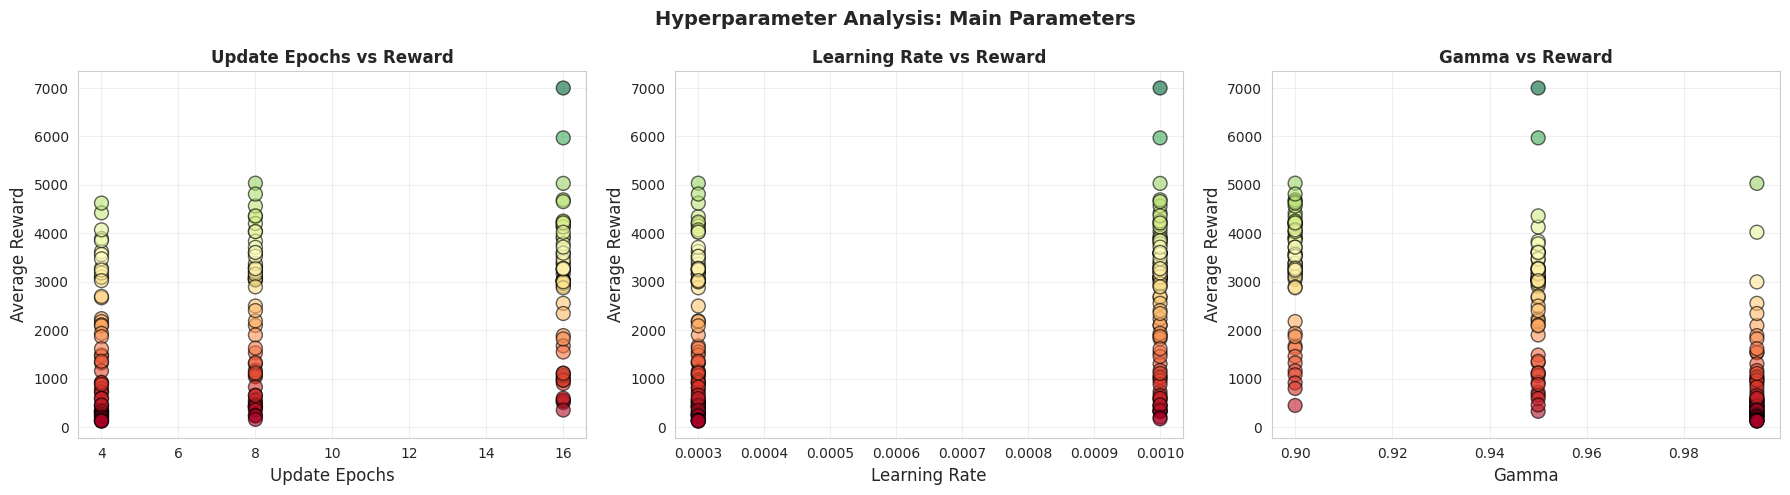

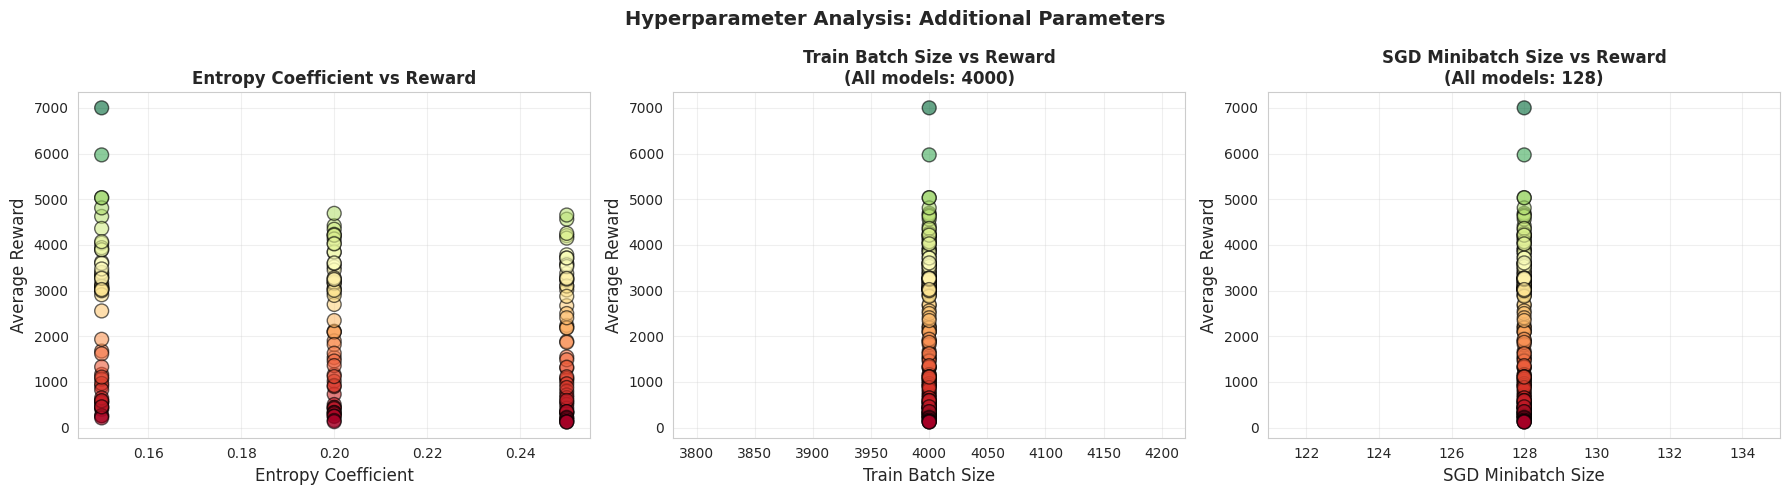

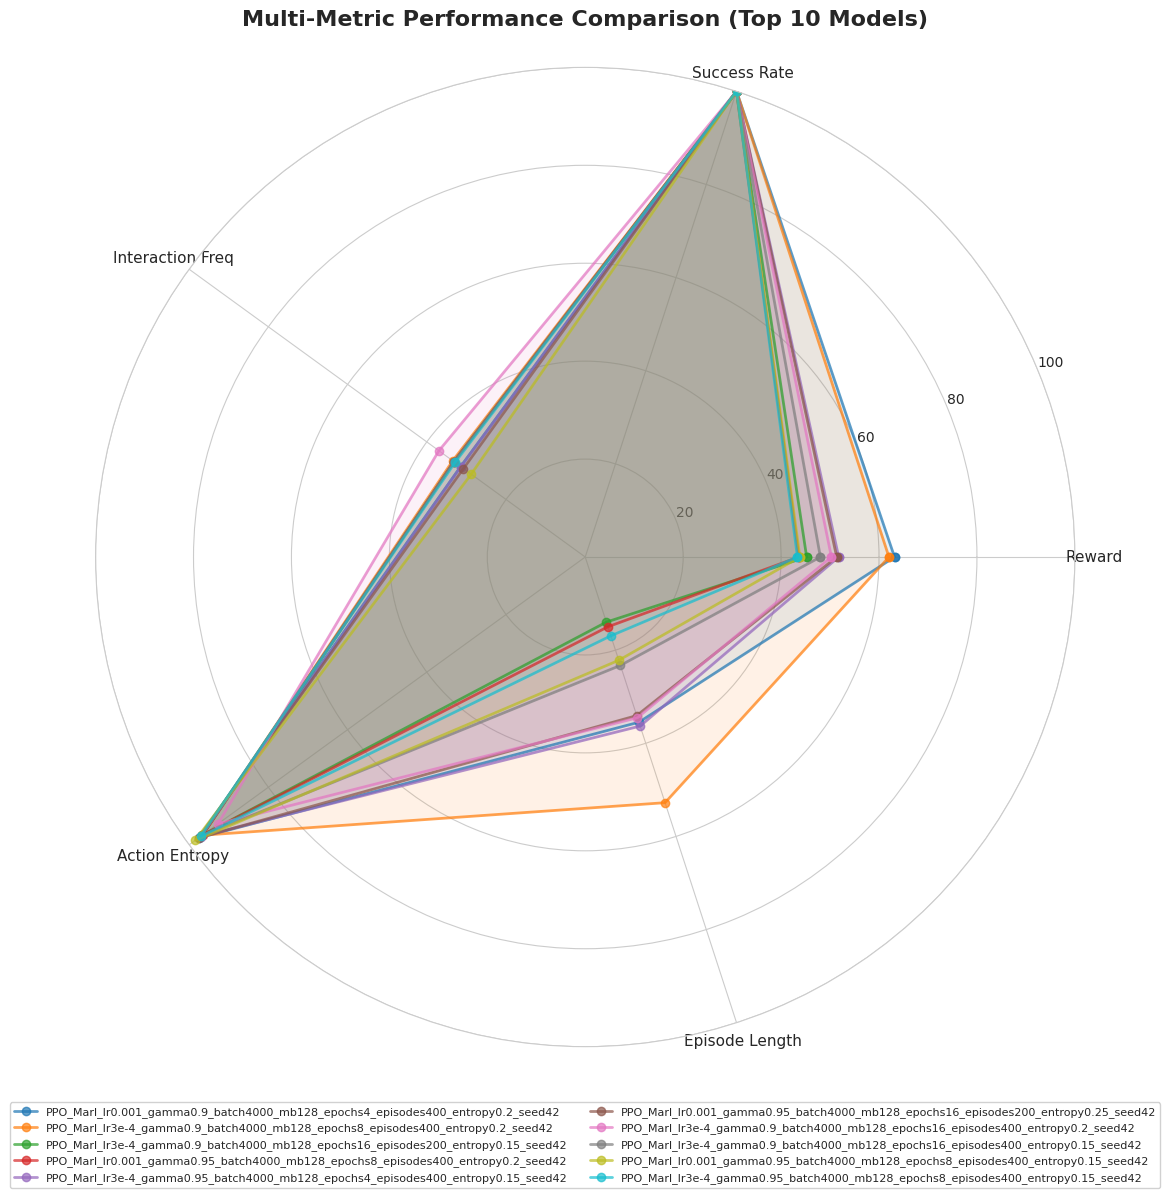

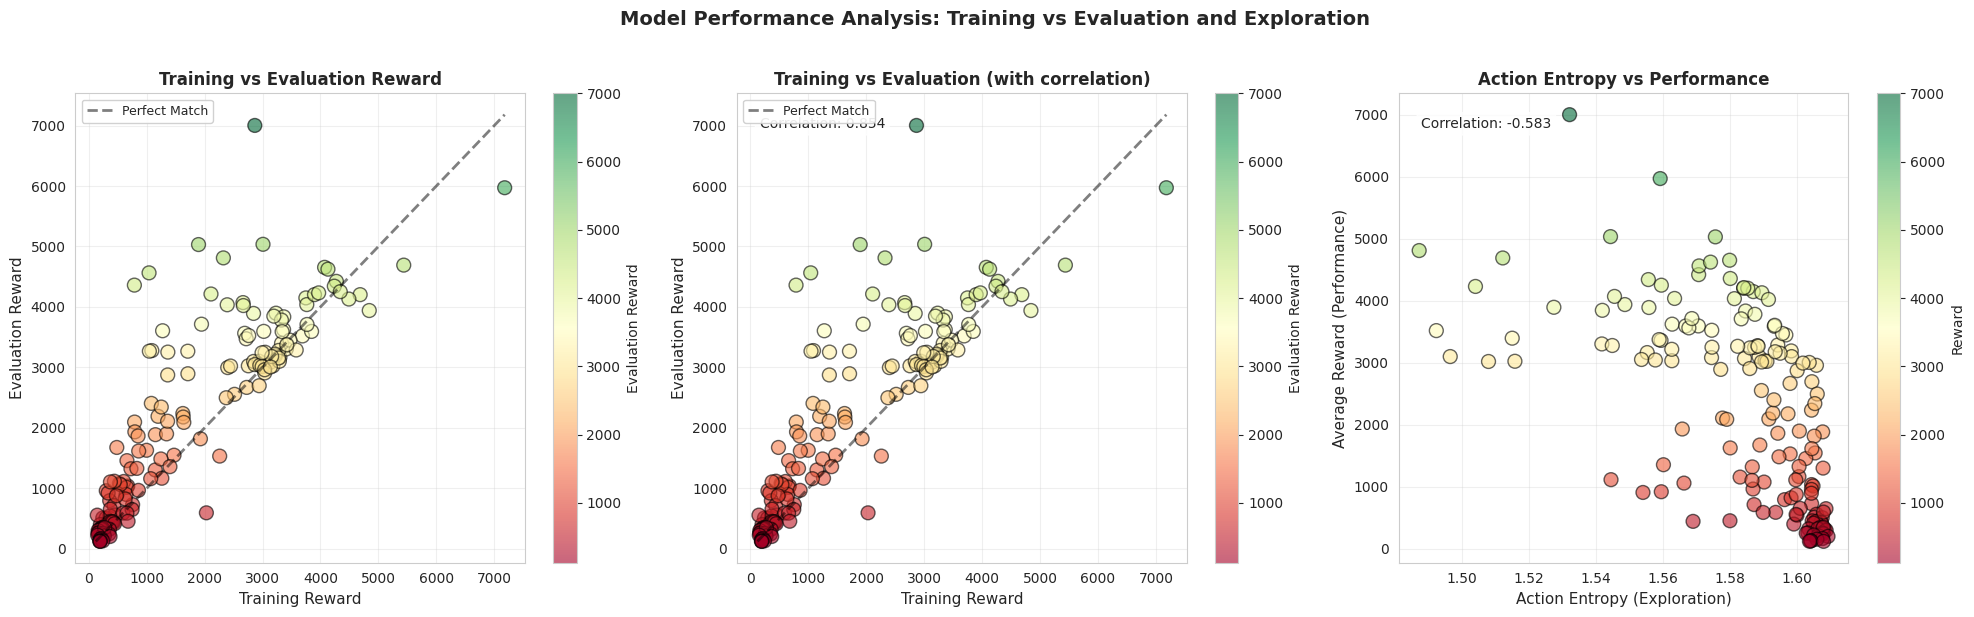

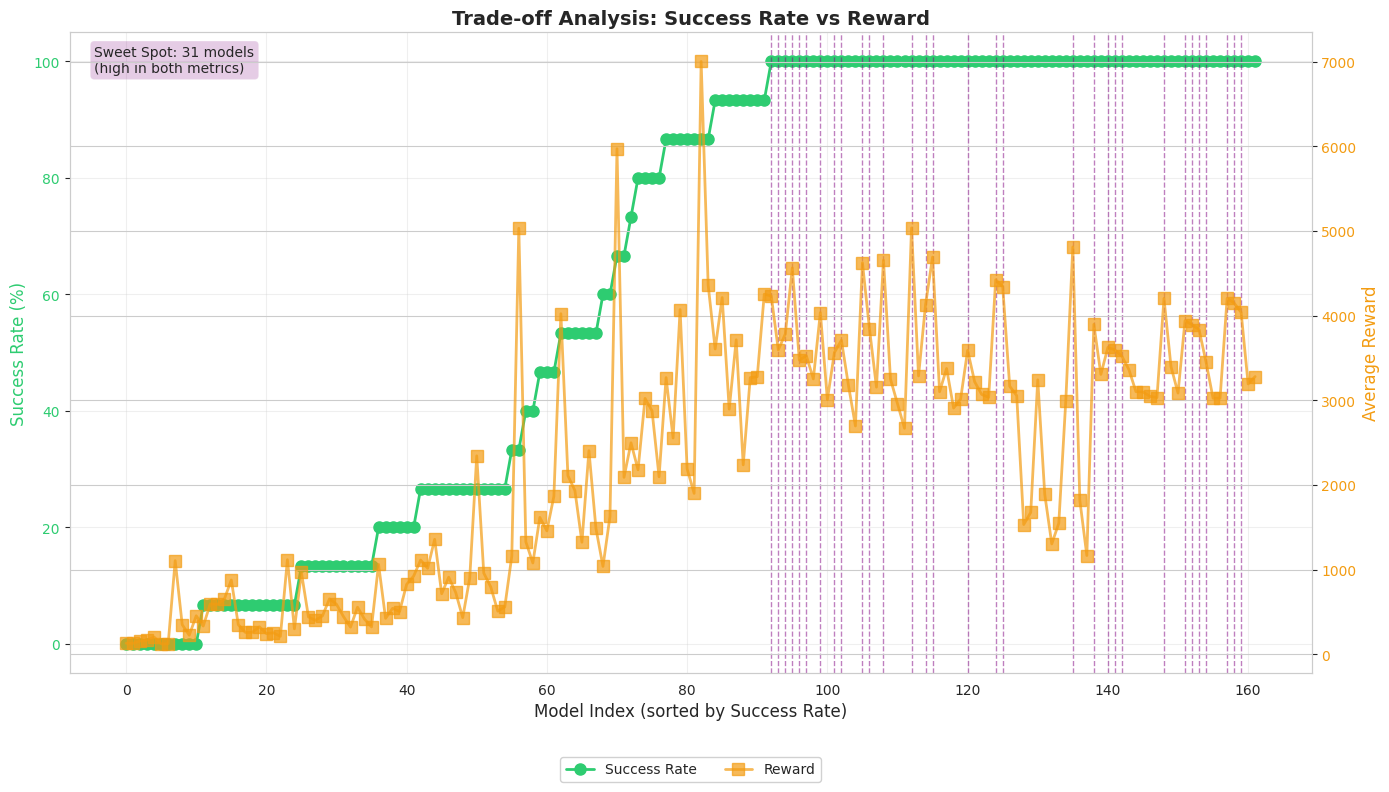

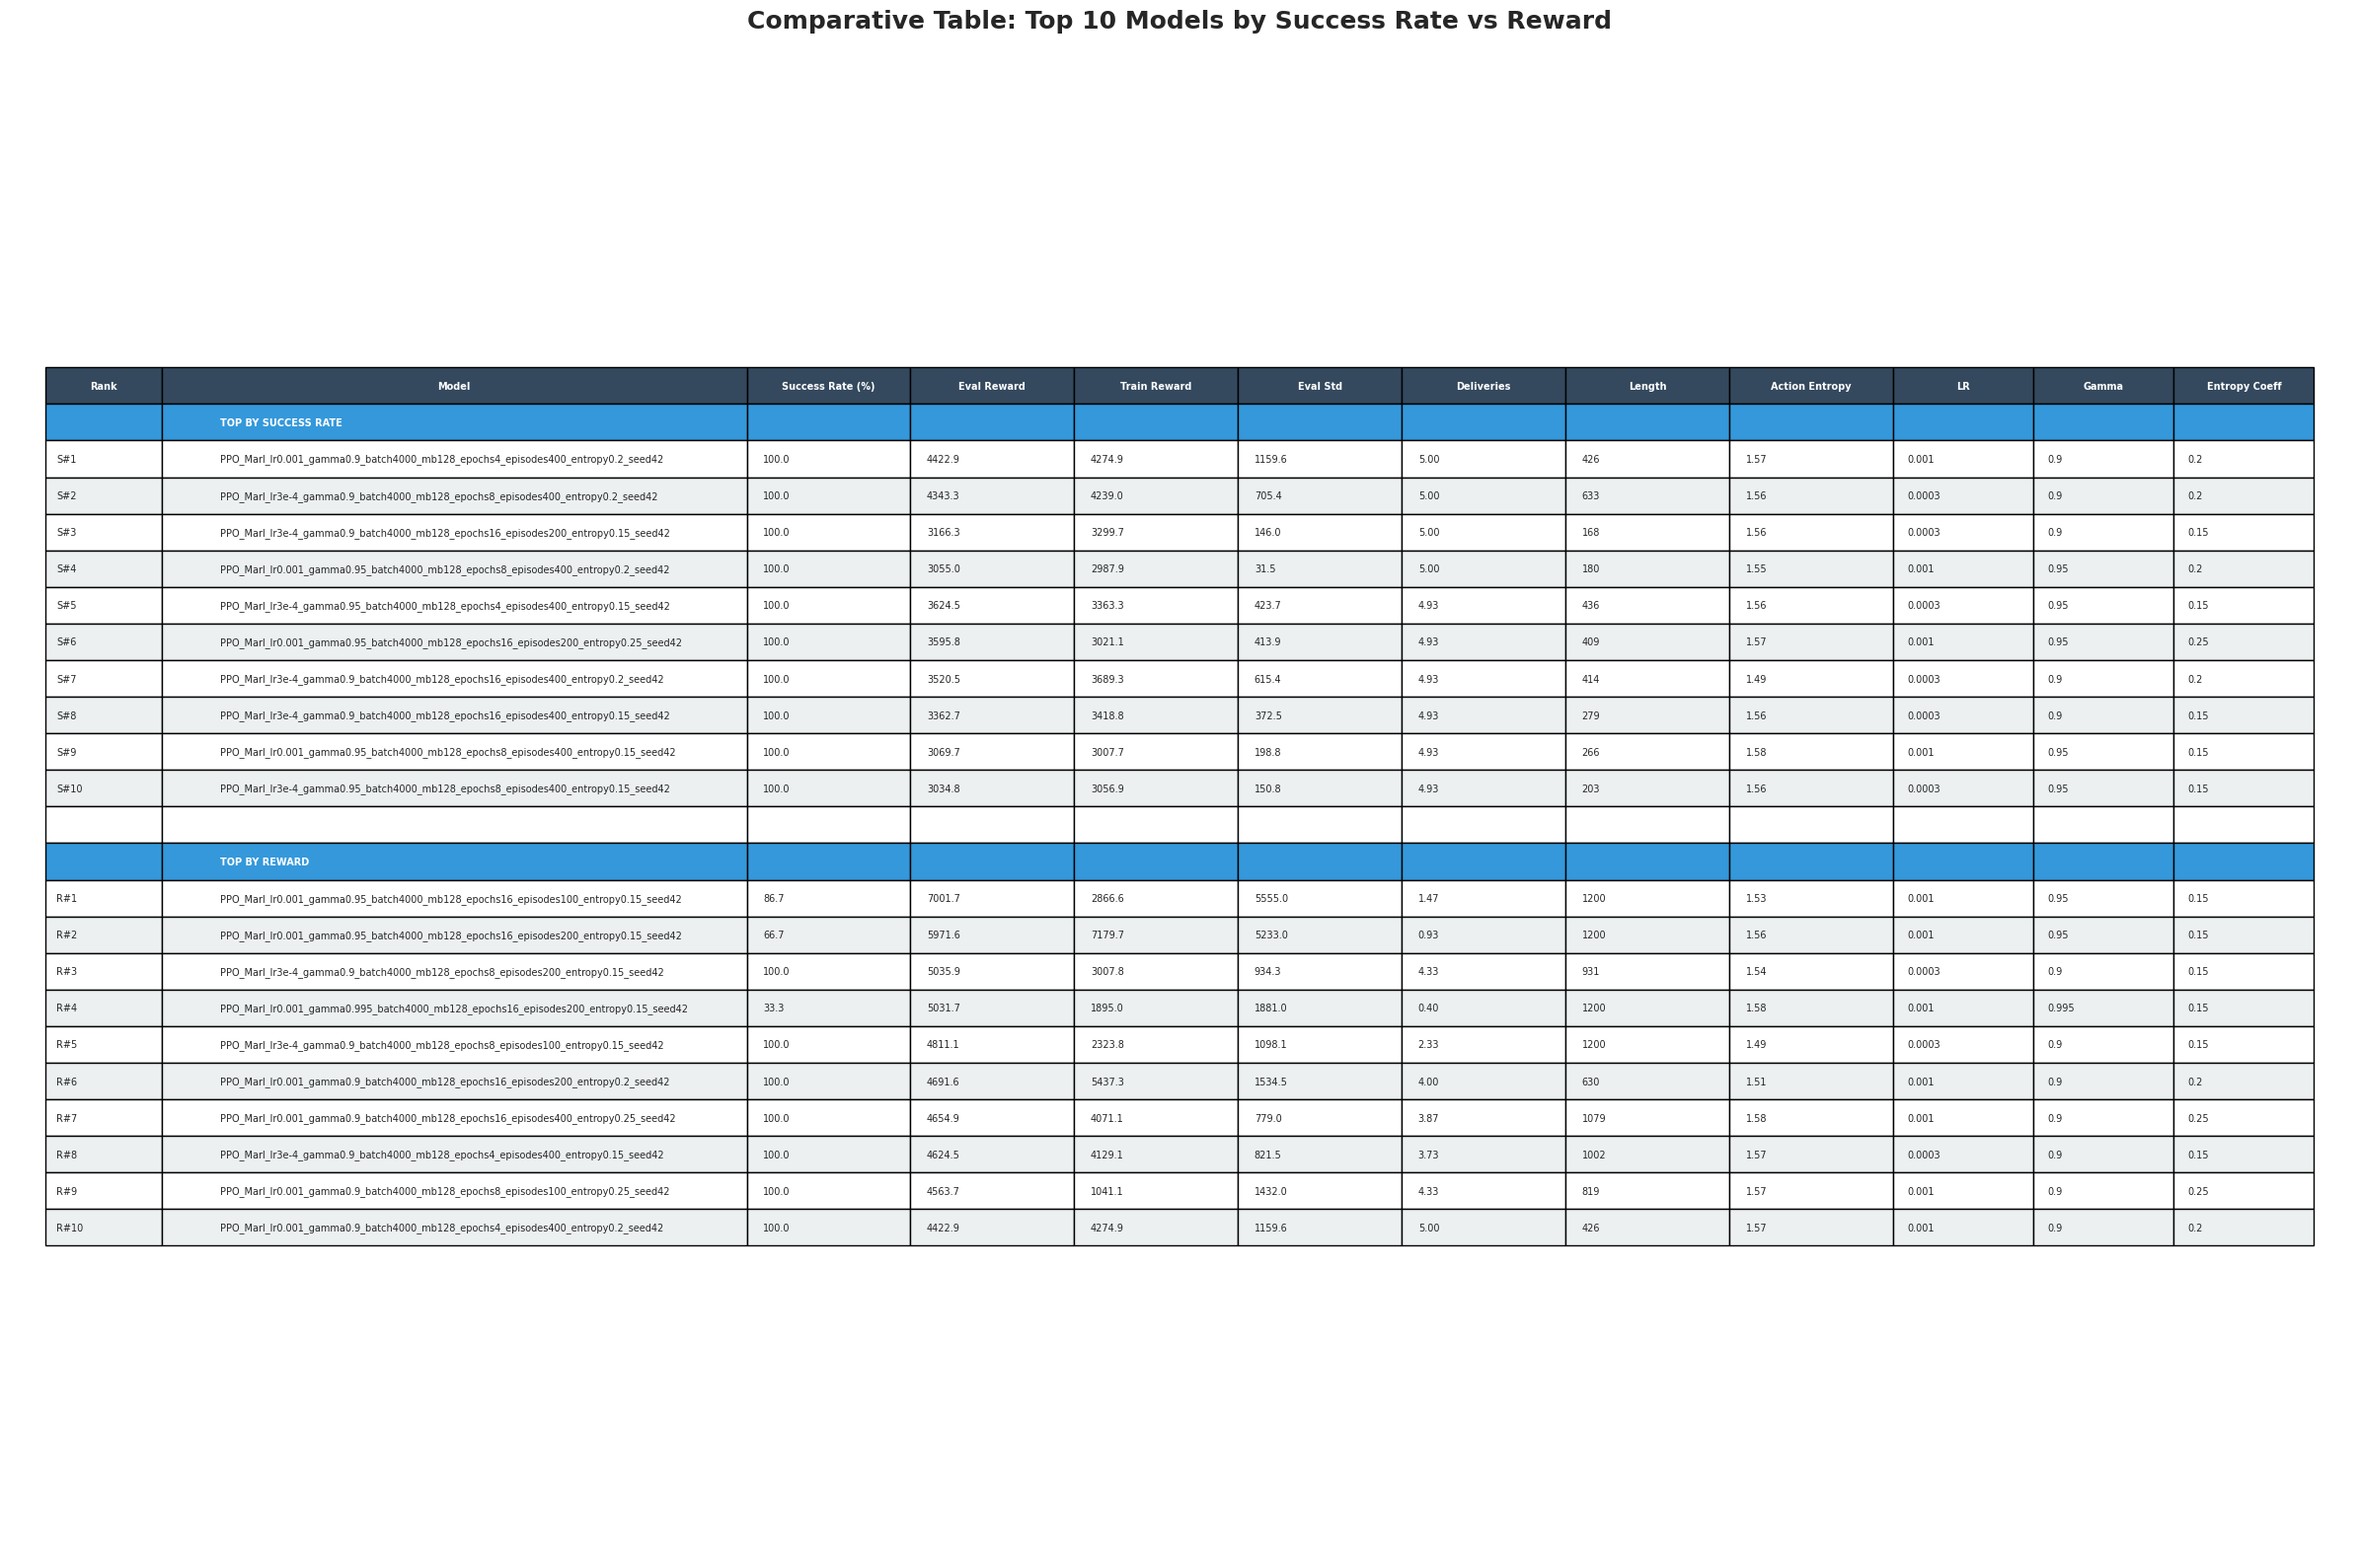

All plots saved in: analysis_output/20251123_230532/


In [7]:
def _load_training_data(exp_dir: Path):
    """Loads training data from an experiment directory."""
    progress_files = list(exp_dir.glob("**/progress.csv"))
    if progress_files:
        try:
            progress_df = pd.read_csv(progress_files[0])
            if 'env_runners/episode_reward_mean' in progress_df.columns:
                reward_col = 'env_runners/episode_reward_mean'
            elif 'env_runners/episode_return_mean' in progress_df.columns:
                reward_col = 'env_runners/episode_return_mean'
            else:
                return None, None
            
            rewards = progress_df[reward_col].dropna().values
            iterations = progress_df['training_iteration'].dropna().values if 'training_iteration' in progress_df.columns else np.arange(len(rewards))
            return rewards, iterations
        except Exception:
            pass
    
    result_files = list(exp_dir.glob("**/result.json"))
    if result_files:
        try:
            with open(result_files[0], 'r') as f:
                results = [json.loads(line) for line in f if line.strip()]
            
            rewards = []
            iterations = []
            for r in results:
                if 'env_runners' in r and isinstance(r['env_runners'], dict):
                    reward = r['env_runners'].get('episode_reward_mean', r['env_runners'].get('episode_return_mean', None))
                    if reward is not None:
                        rewards.append(float(reward))
                        iterations.append(int(r.get('training_iteration', len(iterations) + 1)))
            
            if rewards:
                return np.array(rewards), np.array(iterations)
        except Exception:
            pass
    
    return None, None

def generate_model_display_name(model_dict: Dict, max_length: int = 80, use_full_name: bool = False) -> str:
    """
    Gera nome descritivo do modelo extraindo da hierarquia de pastas ou usando fallback.
    
    A estrutura esperada é:
    ray_results/PPO_Marl_TIMESTAMP/PPO_Marl_lr0.001_gamma0.995_.../PPO_overcooked_marl_parallel_...
    
    Args:
        model_dict: Dicionário com informações do modelo (checkpoint_path, config_name, training_config, params, etc.)
        max_length: Comprimento máximo do nome (será truncado se necessário, ignorado se use_full_name=True)
        use_full_name: Se True, retorna o nome completo sem truncamento (ignora max_length)
    
    Returns:
        String com nome descritivo do modelo
    """
    # Tentar extrair do caminho do checkpoint
    checkpoint_path = model_dict.get('checkpoint_path', '')
    if checkpoint_path:
        try:
            path_obj = Path(checkpoint_path)
            parts = path_obj.parts
            
            # Procurar pela pasta que está um nível abaixo do timestamp
            # Estrutura: .../PPO_Marl_TIMESTAMP/PPO_Marl_lr0.001_.../...
            # Procurar por pasta que começa com PPO_Marl_ e contém parâmetros (tem 'lr', 'gamma', etc.)
            for part in parts:
                if part.startswith('PPO_Marl_') and not part.startswith('PPO_Marl_Config_'):
                    # Verificar se é a pasta de parâmetros (contém indicadores de parâmetros no nome)
                    if 'lr' in part or 'gamma' in part or 'batch' in part or 'mb' in part or 'epochs' in part or 'entropy' in part or 'seed' in part:
                        # Encontrou o diretório com parâmetros (um nível abaixo do timestamp)
                        display_name = part
                        
                        # Se use_full_name=False, truncar se necessário
                        if not use_full_name and max_length and len(display_name) > max_length:
                            display_name = display_name[:max_length-3] + "..."
                        
                        return display_name
        except Exception:
            pass
    
    # Fallback: usar config_name + parâmetros de training_config
    config_name = model_dict.get('config_name', 'Unknown')
    training_config = model_dict.get('training_config', {})
    params = model_dict.get('params', {})
    
    # Combinar parâmetros principais
    param_parts = []
    
    if 'learning_rate' in training_config:
        lr = training_config['learning_rate']
        param_parts.append(f"lr={lr:.4f}".rstrip('0').rstrip('.'))
    elif 'learning_rate' in params:
        lr = params['learning_rate']
        param_parts.append(f"lr={lr:.4f}".rstrip('0').rstrip('.'))
    
    if 'gamma' in training_config:
        gamma = training_config['gamma']
        param_parts.append(f"γ={gamma:.3f}".rstrip('0').rstrip('.'))
    elif 'gamma' in params:
        gamma = params['gamma']
        param_parts.append(f"γ={gamma:.3f}".rstrip('0').rstrip('.'))
    
    if 'train_batch_size' in training_config:
        param_parts.append(f"batch={training_config['train_batch_size']}")
    
    if 'sgd_minibatch_size' in training_config:
        param_parts.append(f"mb={training_config['sgd_minibatch_size']}")
    
    if 'num_epochs' in training_config:
        param_parts.append(f"epochs={training_config['num_epochs']}")
    elif 'update_epochs' in training_config:
        param_parts.append(f"epochs={training_config['update_epochs']}")
    
    if 'entropy_coeff' in training_config:
        entropy = training_config['entropy_coeff']
        param_parts.append(f"entropy={entropy:.2f}".rstrip('0').rstrip('.'))
    elif 'entropy_coeff' in params:
        entropy = params['entropy_coeff']
        param_parts.append(f"entropy={entropy:.2f}".rstrip('0').rstrip('.'))
    
    if param_parts:
        display_name = f"{config_name} | {', '.join(param_parts)}"
    else:
        display_name = config_name
    
    # Truncar se necessário (apenas se use_full_name=False)
    if not use_full_name and max_length and len(display_name) > max_length:
        display_name = display_name[:max_length-3] + "..."
    
    return display_name

def generate_analysis_plots(evaluation_results: List[Dict]):
    """Generates analysis plots of evaluated models."""
    if not evaluation_results:
        print("No results to visualize!")
        return
    
    # Criar subpasta com timestamp
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    base_output_dir = Path("analysis_output")
    base_output_dir.mkdir(exist_ok=True)
    output_dir = base_output_dir / timestamp
    output_dir.mkdir(exist_ok=True)
    
    print(f"Salvando gráficos em: {output_dir}")
    
    df = pd.DataFrame(evaluation_results)
    df = df.sort_values(['mean_deliveries', 'mean_reward'], ascending=[False, False]).reset_index(drop=True)
    
    # ========== PLOT 1: Horizontal Ranking by Deliveries ==========
    try:
        # Mostrar top 20 modelos
        top_n = min(20, len(df))
        df_top = df.head(top_n).copy()
        
        # Gerar nomes descritivos
        display_names = []
        for _, row in df_top.iterrows():
            model_dict = row.to_dict()
            display_names.append(generate_model_display_name(model_dict, use_full_name=True))
        
        fig, ax = plt.subplots(figsize=(16, max(10, top_n * 0.5)))
        colors = plt.cm.RdYlGn(np.linspace(0.2, 0.8, len(df_top)))
        bars = ax.barh(range(len(df_top)), df_top['mean_deliveries'], color=colors)
        
        # Highlight top 3
        if len(bars) > 0:
            bars[0].set_color('gold')
            bars[0].set_edgecolor('darkgoldenrod')
            bars[0].set_linewidth(2)
        if len(bars) > 1:
            bars[1].set_color('silver')
            bars[1].set_edgecolor('gray')
            bars[1].set_linewidth(2)
        if len(bars) > 2:
            bars[2].set_color('#CD7F32')
            bars[2].set_edgecolor('brown')
            bars[2].set_linewidth(2)
        
        ax.set_yticks(range(len(df_top)))
        ax.set_yticklabels(display_names, fontsize=8)
        ax.set_xlabel('Average Deliveries', fontsize=12)
        ax.set_title('Model Ranking by Average Deliveries (Top 20)', fontsize=14, fontweight='bold')
        ax.grid(True, alpha=0.3, axis='x')
        
        for i, (bar, deliveries) in enumerate(zip(bars, df_top['mean_deliveries'])):
            ax.text(deliveries + max(df_top['mean_deliveries']) * 0.01, bar.get_y() + bar.get_height()/2, 
                   f'{deliveries:.2f}', va='center', fontsize=9, fontweight='bold')
        
        plt.tight_layout()
        plt.savefig(output_dir / "1_ranking_deliveries.png", dpi=150, bbox_inches='tight')
        plt.show()
    except Exception as e:
        print(f"Error in Plot 1: {e}")
    
    # ========== PLOT 2: Learning Curves ==========
    try:
        fig, ax = plt.subplots(figsize=(16, 10))
        top_n = min(20, len(df))
        colors = plt.cm.tab20(np.linspace(0, 1, top_n))
        
        has_data = False
        ray_results_dir = Path("ray_results")
        available_exp_dirs = sorted([d for d in ray_results_dir.iterdir() if d.is_dir() and (d.name.startswith('PPO_Marl_Config_') or d.name.startswith('PPO_Marl_'))]) if ray_results_dir.exists() else []
        
        for i in range(top_n):
            row = df.iloc[i]
            config_name = row.get('config_name', '')
            checkpoint_path = row.get('checkpoint_path', '')
            model_dir = row.get('model_dir', '')
            
            # Gerar nome descritivo
            model_dict = row.to_dict()
            display_name = generate_model_display_name(model_dict, use_full_name=True)
            
            exp_dir = None
            
            # Usar model_dir diretamente (já contém o diretório do trial com progress.csv)
            if model_dir:
                try:
                    model_dir_path = Path(model_dir)
                    if model_dir_path.exists():
                        # Verificar se tem progress.csv diretamente
                        if (model_dir_path / "progress.csv").exists() or (model_dir_path / "result.json").exists():
                            exp_dir = model_dir_path
                        else:
                            # Buscar em subdiretórios (caso o progress.csv esteja em subdiretório)
                            for subdir in model_dir_path.iterdir():
                                if subdir.is_dir() and ((subdir / "progress.csv").exists() or (subdir / "result.json").exists()):
                                    exp_dir = subdir
                                    break
                except Exception:
                    pass
            
            # Fallback: buscar a partir do checkpoint_path
            if not exp_dir and checkpoint_path:
                try:
                    checkpoint_path_obj = Path(checkpoint_path)
                    # Subir na hierarquia até encontrar progress.csv
                    current_dir = checkpoint_path_obj.parent
                    max_levels = 5
                    for level in range(max_levels):
                        if current_dir.exists():
                            if (current_dir / "progress.csv").exists() or (current_dir / "result.json").exists():
                                exp_dir = current_dir
                                break
                        if current_dir.parent == current_dir:  # Chegou na raiz
                            break
                        current_dir = current_dir.parent
                except Exception:
                    pass
            
            if exp_dir and exp_dir.exists():
                rewards, iterations = _load_training_data(exp_dir)
                if rewards is not None and len(rewards) > 0:
                    window = max(1, min(10, len(rewards) // 5))
                    smoothed = pd.Series(rewards).rolling(window=window, min_periods=1).mean().values
                    ax.plot(iterations[:len(smoothed)], smoothed, color=colors[i], linewidth=2, 
                           label=display_name, alpha=0.8)
                    has_data = True
        
        if not has_data:
            ax.text(0.5, 0.5, 'Learning curves not available\n\n' + 
                   'Training data was not found in ray_results/.\n' +
                   'Check if progress.csv or result.json files exist in the directories\n' +
                   'of experiments in ray_results/.', 
                   transform=ax.transAxes, ha='center', va='center', fontsize=11, style='italic',
                   bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
        else:
            ax.set_xlabel('Training Iteration', fontsize=12)
            ax.set_ylabel('Reward (smoothed)', fontsize=12)
            # Legenda na parte inferior com nomes completos
            ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=1, fontsize=7, framealpha=0.9)
            ax.grid(True, alpha=0.3)
        
        ax.set_title('Learning Curves - Top 20 Models', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig(output_dir / "2_learning_curves.png", dpi=150, bbox_inches='tight')
        plt.show()
    except Exception as e:
        print(f"Error in Plot 2: {e}")
    
    # ========== PLOT 3: Action Distribution ==========
    try:
        fig, axes = plt.subplots(2, 2, figsize=(14, 12))
        axes = axes.flatten()
        top_n = min(4, len(df))
        
        action_names = ['Up', 'Down', 'Left', 'Right', 'Interact']
        
        for i in range(top_n):
            row = df.iloc[i]
            action_dist = row.get('action_distribution', {})
            
            # Gerar nome descritivo completo (sem truncamento)
            model_dict = row.to_dict()
            display_name = generate_model_display_name(model_dict, use_full_name=True)
            
            if action_dist:
                actions = [action_dist.get(j, 0) for j in range(5)]
                total = sum(actions)
                if total > 0:
                    percentages = [a / total * 100 for a in actions]
                    ax = axes[i]
                    bars = ax.bar(action_names, percentages, color=plt.cm.Set3(range(5)))
                    ax.set_title(display_name, fontsize=9, fontweight='bold', wrap=True)
                    ax.set_ylabel('Percentage', fontsize=10)
                    ax.set_ylim(0, max(percentages) * 1.2 if percentages else 100)
                    for bar, pct in zip(bars, percentages):
                        if pct > 1:
                            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, 
                                   f'{pct:.1f}%', ha='center', va='bottom', fontsize=8)
                    ax.grid(True, alpha=0.3, axis='y')
        
        for i in range(top_n, len(axes)):
            axes[i].axis('off')
        
        plt.suptitle('Action Distribution - Top 4 Models', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig(output_dir / "3_action_distribution.png", dpi=150, bbox_inches='tight')
        plt.show()
    except Exception as e:
        print(f"Error in Plot 3: {e}")
    
    # ========== PLOT 4: Hyperparameter Analysis ==========
    try:
        if 'params' in df.columns and df['params'].notna().any() or 'training_config' in df.columns:
            hyperparams = []
            for _, row in df.iterrows():
                params = row.get('params', {}) if isinstance(row.get('params'), dict) else {}
                training_config = row.get('training_config', {}) if isinstance(row.get('training_config'), dict) else {}
                
                # Função auxiliar para extrair valor com fallback, tratando 0 como valor válido
                def get_value(*keys, default=np.nan):
                    for key in keys:
                        if key in training_config and training_config[key] is not None:
                            return training_config[key]
                        if key in params and params[key] is not None:
                            return params[key]
                    return default
                
                # Extrair hiperparâmetros priorizando training_config, depois params
                # Usar np.nan para valores ausentes (não usar 0, pois 0 pode ser um valor válido)
                learning_rate = get_value('learning_rate', 'lr')
                gamma = get_value('gamma')
                train_batch_size = get_value('train_batch_size')
                sgd_minibatch_size = get_value('sgd_minibatch_size')
                num_epochs = get_value('num_epochs', 'update_epochs')
                entropy_coeff = get_value('entropy_coeff')
                num_episodes = get_value('num_episodes')
                
                # Combinar params e training_config
                # Usar np.nan para valores ausentes (não 0)
                hp_dict = {
                    'learning_rate': learning_rate,
                    'gamma': gamma,
                    'train_batch_size': train_batch_size,
                    'sgd_minibatch_size': sgd_minibatch_size,
                    'num_epochs': num_epochs,
                    'entropy_coeff': entropy_coeff,
                    'num_episodes': num_episodes,
                    'reward': row['mean_reward']
                }
                hyperparams.append(hp_dict)
            
            hp_df = pd.DataFrame(hyperparams)
            
            if len(hp_df) > 0 and hp_df['reward'].sum() > 0:
                # Primeira figura: Update Epochs, Learning Rate, Gamma (lado a lado)
                fig1, axes1 = plt.subplots(1, 3, figsize=(18, 5))
                
                # Sempre mostrar os gráficos, mesmo se houver pouca variação
                if 'num_epochs' in hp_df.columns and hp_df['num_epochs'].notna().any():
                    axes1[0].scatter(hp_df['num_epochs'], hp_df['reward'], 
                                   s=100, alpha=0.6, c=hp_df['reward'], cmap='RdYlGn', 
                                   edgecolors='black', linewidth=1)
                    axes1[0].set_xlabel('Update Epochs', fontsize=12)
                    axes1[0].set_ylabel('Average Reward', fontsize=12)
                    title = 'Update Epochs vs Reward'
                    if hp_df['num_epochs'].nunique() == 1:
                        title += f'\n(All models: {hp_df["num_epochs"].iloc[0]})'
                    axes1[0].set_title(title, fontsize=12, fontweight='bold')
                    axes1[0].grid(True, alpha=0.3)
                else:
                    axes1[0].axis('off')
                    axes1[0].text(0.5, 0.5, 'No data', ha='center', va='center', transform=axes1[0].transAxes)
                
                if 'learning_rate' in hp_df.columns and hp_df['learning_rate'].notna().any():
                    axes1[1].scatter(hp_df['learning_rate'], hp_df['reward'], 
                                   s=100, alpha=0.6, c=hp_df['reward'], cmap='RdYlGn', 
                                   edgecolors='black', linewidth=1)
                    axes1[1].set_xlabel('Learning Rate', fontsize=12)
                    axes1[1].set_ylabel('Average Reward', fontsize=12)
                    title = 'Learning Rate vs Reward'
                    if hp_df['learning_rate'].nunique() == 1:
                        title += f'\n(All models: {hp_df["learning_rate"].iloc[0]:.4f})'
                    axes1[1].set_title(title, fontsize=12, fontweight='bold')
                    axes1[1].grid(True, alpha=0.3)
                else:
                    axes1[1].axis('off')
                    axes1[1].text(0.5, 0.5, 'No data', ha='center', va='center', transform=axes1[1].transAxes)
                
                if 'gamma' in hp_df.columns and hp_df['gamma'].notna().any():
                    axes1[2].scatter(hp_df['gamma'], hp_df['reward'], 
                                   s=100, alpha=0.6, c=hp_df['reward'], cmap='RdYlGn', 
                                   edgecolors='black', linewidth=1)
                    axes1[2].set_xlabel('Gamma', fontsize=12)
                    axes1[2].set_ylabel('Average Reward', fontsize=12)
                    title = 'Gamma vs Reward'
                    if hp_df['gamma'].nunique() == 1:
                        title += f'\n(All models: {hp_df["gamma"].iloc[0]:.3f})'
                    axes1[2].set_title(title, fontsize=12, fontweight='bold')
                    axes1[2].grid(True, alpha=0.3)
                else:
                    axes1[2].axis('off')
                    axes1[2].text(0.5, 0.5, 'No data', ha='center', va='center', transform=axes1[2].transAxes)
                
                plt.suptitle('Hyperparameter Analysis: Main Parameters', fontsize=14, fontweight='bold')
                plt.tight_layout()
                plt.savefig(output_dir / "4a_hyperparameter_main.png", dpi=150, bbox_inches='tight')
                plt.show()
                
                # Segunda figura: Novos parâmetros (Entropy, Batch Size, SGD Minibatch) - layout 1x3
                fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))
                
                if 'entropy_coeff' in hp_df.columns and hp_df['entropy_coeff'].notna().any():
                    axes2[0].scatter(hp_df['entropy_coeff'], hp_df['reward'], 
                                     s=100, alpha=0.6, c=hp_df['reward'], cmap='RdYlGn', 
                                     edgecolors='black', linewidth=1)
                    axes2[0].set_xlabel('Entropy Coefficient', fontsize=12)
                    axes2[0].set_ylabel('Average Reward', fontsize=12)
                    title = 'Entropy Coefficient vs Reward'
                    if hp_df['entropy_coeff'].nunique() == 1:
                        title += f'\n(All models: {hp_df["entropy_coeff"].iloc[0]:.2f})'
                    axes2[0].set_title(title, fontsize=12, fontweight='bold')
                    axes2[0].grid(True, alpha=0.3)
                else:
                    axes2[0].axis('off')
                    axes2[0].text(0.5, 0.5, 'No data', ha='center', va='center', transform=axes2[0].transAxes)
                
                if 'train_batch_size' in hp_df.columns and hp_df['train_batch_size'].notna().any():
                    axes2[1].scatter(hp_df['train_batch_size'], hp_df['reward'], 
                                     s=100, alpha=0.6, c=hp_df['reward'], cmap='RdYlGn', 
                                     edgecolors='black', linewidth=1)
                    axes2[1].set_xlabel('Train Batch Size', fontsize=12)
                    axes2[1].set_ylabel('Average Reward', fontsize=12)
                    title = 'Train Batch Size vs Reward'
                    if hp_df['train_batch_size'].nunique() == 1:
                        title += f'\n(All models: {hp_df["train_batch_size"].iloc[0]})'
                    axes2[1].set_title(title, fontsize=12, fontweight='bold')
                    axes2[1].grid(True, alpha=0.3)
                else:
                    axes2[1].axis('off')
                    axes2[1].text(0.5, 0.5, 'No data', ha='center', va='center', transform=axes2[1].transAxes)
                
                if 'sgd_minibatch_size' in hp_df.columns and hp_df['sgd_minibatch_size'].notna().any():
                    axes2[2].scatter(hp_df['sgd_minibatch_size'], hp_df['reward'], 
                                     s=100, alpha=0.6, c=hp_df['reward'], cmap='RdYlGn', 
                                     edgecolors='black', linewidth=1)
                    axes2[2].set_xlabel('SGD Minibatch Size', fontsize=12)
                    axes2[2].set_ylabel('Average Reward', fontsize=12)
                    title = 'SGD Minibatch Size vs Reward'
                    if hp_df['sgd_minibatch_size'].nunique() == 1:
                        title += f'\n(All models: {hp_df["sgd_minibatch_size"].iloc[0]})'
                    axes2[2].set_title(title, fontsize=12, fontweight='bold')
                    axes2[2].grid(True, alpha=0.3)
                else:
                    axes2[2].axis('off')
                    axes2[2].text(0.5, 0.5, 'No data', ha='center', va='center', transform=axes2[2].transAxes)
                
                plt.suptitle('Hyperparameter Analysis: Additional Parameters', fontsize=14, fontweight='bold')
                plt.tight_layout()
                plt.savefig(output_dir / "4b_hyperparameter_additional.png", dpi=150, bbox_inches='tight')
                plt.show()
    except Exception as e:
        print(f"Error in Plot 4: {e}")
    
    
    # ========== PLOT 5: Radar Chart (Multi-Metric Performance Comparison) ==========
    try:
        if len(df) > 0:
            top_n = min(10, len(df))
            # Métricas melhoradas: Reward, Success Rate, Interaction Frequency, Action Entropy, Episode Length (normalizado)
            categories = ['Reward', 'Success Rate', 'Interaction Freq', 'Action Entropy', 'Episode Length']
            
            fig, ax = plt.subplots(figsize=(14, 12), subplot_kw=dict(projection='polar'))
            
            angles = np.linspace(0, 2 * np.pi, len(categories), endpoint=False).tolist()
            angles += angles[:1]
            
            # Gerar nomes descritivos
            display_names = []
            for i in range(top_n):
                row = df.iloc[i]
                model_dict = row.to_dict()
                display_name = generate_model_display_name(model_dict, use_full_name=True)
                display_names.append(display_name)
            
            colors = plt.cm.tab10(np.linspace(0, 1, top_n))
            
            for i in range(top_n):
                row = df.iloc[i]
                interaction_freq = row.get('interaction_frequency', 0) * 100
                action_entropy = row.get('action_entropy', 0) if 'action_entropy' in row else 0
                mean_length = row.get('mean_length', 0)
                
                # Normalizar valores para 0-100
                max_reward = df['mean_reward'].max() if df['mean_reward'].max() > 0 else 1
                max_entropy = df['action_entropy'].max() if 'action_entropy' in df.columns and df['action_entropy'].max() > 0 else 1
                max_length_val = df['mean_length'].max() if df['mean_length'].max() > 0 else 1
                
                values = [
                    (row['mean_reward'] / max_reward) * 100,
                    row['success_rate'] * 100,
                    interaction_freq,
                    (action_entropy / max_entropy) * 100 if max_entropy > 0 else 0,
                    (mean_length / max_length_val) * 100 if max_length_val > 0 else 0
                ]
                values += values[:1]
                
                ax.plot(angles, values, 'o-', linewidth=2, label=display_names[i], alpha=0.7, color=colors[i])
                ax.fill(angles, values, alpha=0.1, color=colors[i])
            
            ax.set_xticks(angles[:-1])
            ax.set_xticklabels(categories, fontsize=11)
            ax.set_ylim(0, 100)
            ax.set_title('Multi-Metric Performance Comparison (Top 10 Models)', fontsize=16, fontweight='bold', pad=30)
            # Mover legenda para parte inferior
            ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=8, framealpha=0.9)
            ax.grid(True)
            
            plt.tight_layout()
            plt.savefig(output_dir / "5_radar_chart.png", dpi=150, bbox_inches='tight')
            plt.show()
    except Exception as e:
        print(f"Error in Plot 5: {e}")
    
    # ========== PLOT 6-8: Combined Analysis (Training vs Eval, Training vs Eval with Correlation, Action Entropy) ==========
    try:
        # Criar figura com 3 subplots lado a lado (1x3 layout)
        fig, axes = plt.subplots(1, 3, figsize=(20, 6))
        
        # ========== PLOT 6: Training vs Evaluation Reward (simple) ==========
        if 'training_reward' in df.columns and df['training_reward'].sum() > 0:
            ax1 = axes[0]
            scatter1 = ax1.scatter(df['training_reward'], df['mean_reward'], s=100, alpha=0.6, 
                      c=df['mean_reward'], cmap='RdYlGn', edgecolors='black', linewidth=1)
            
            min_val = min(df['training_reward'].min(), df['mean_reward'].min())
            max_val = max(df['training_reward'].max(), df['mean_reward'].max())
            ax1.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5, linewidth=2, 
                   label='Perfect Match')
            
            ax1.set_xlabel('Training Reward', fontsize=11)
            ax1.set_ylabel('Evaluation Reward', fontsize=11)
            ax1.set_title('Training vs Evaluation Reward', fontsize=12, fontweight='bold')
            ax1.legend(loc='upper left', fontsize=9, framealpha=0.9)
            ax1.grid(True, alpha=0.3)
            plt.colorbar(scatter1, ax=ax1, label='Evaluation Reward')
        
        # ========== PLOT 7: Training vs Evaluation Reward (with correlation) ==========
        if 'training_reward' in df.columns and df['training_reward'].sum() > 0:
            ax2 = axes[1]
            scatter2 = ax2.scatter(df['training_reward'], df['mean_reward'], s=100, alpha=0.6, 
                      c=df['mean_reward'], cmap='RdYlGn', edgecolors='black', linewidth=1)
            
            min_val = min(df['training_reward'].min(), df['mean_reward'].min())
            max_val = max(df['training_reward'].max(), df['mean_reward'].max())
            ax2.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5, linewidth=2, 
                   label='Perfect Match')
            
            # Calcular correlação
            if len(df) > 1:
                try:
                    corr = np.corrcoef(df['training_reward'], df['mean_reward'])[0, 1]
                    if not np.isnan(corr) and not np.isinf(corr):
                        ax2.text(0.05, 0.95, f'Correlation: {corr:.3f}', transform=ax2.transAxes, 
                               fontsize=10, verticalalignment='top',
                               bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
                except Exception:
                    pass
            
            ax2.set_xlabel('Training Reward', fontsize=11)
            ax2.set_ylabel('Evaluation Reward', fontsize=11)
            ax2.set_title('Training vs Evaluation (with correlation)', fontsize=12, fontweight='bold')
            ax2.legend(loc='upper left', fontsize=9, framealpha=0.9)
            ax2.grid(True, alpha=0.3)
            plt.colorbar(scatter2, ax=ax2, label='Evaluation Reward')
        
        # ========== PLOT 8: Action Entropy vs Performance ==========
        if len(df) > 0 and 'action_entropy' in df.columns:
            ax3 = axes[2]
            scatter3 = ax3.scatter(df['action_entropy'], df['mean_reward'], 
                              s=100, alpha=0.6, c=df['mean_reward'], cmap='RdYlGn', 
                              edgecolors='black', linewidth=1)
            
            # Calcular correlação
            if len(df) > 1:
                try:
                    corr = np.corrcoef(df['action_entropy'], df['mean_reward'])[0, 1]
                    if not np.isnan(corr) and not np.isinf(corr):
                        ax3.text(0.05, 0.95, f'Correlation: {corr:.3f}', transform=ax3.transAxes, 
                               fontsize=10, verticalalignment='top',
                               bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
                except Exception:
                    pass
            
            ax3.set_xlabel('Action Entropy (Exploration)', fontsize=11)
            ax3.set_ylabel('Average Reward (Performance)', fontsize=11)
            ax3.set_title('Action Entropy vs Performance', fontsize=12, fontweight='bold')
            ax3.grid(True, alpha=0.3)
            plt.colorbar(scatter3, ax=ax3, label='Reward')
        
        plt.suptitle('Model Performance Analysis: Training vs Evaluation and Exploration', 
                    fontsize=14, fontweight='bold', y=1.02)
        plt.tight_layout()
        plt.savefig(output_dir / "6-8_combined_analysis.png", dpi=150, bbox_inches='tight')
        plt.show()
    except Exception as e:
        print(f"Error in Plot 6-8: {e}")
    
    # ========== PLOT 13: Trade-off Analysis ==========
    try:
        if len(df) > 0:
            df_sorted = df.sort_values('success_rate', ascending=True).reset_index(drop=True)
            
            fig, ax1 = plt.subplots(figsize=(14, 8))
            
            color1 = '#2ecc71'
            ax1.set_xlabel('Model Index (sorted by Success Rate)', fontsize=12)
            ax1.set_ylabel('Success Rate (%)', color=color1, fontsize=12)
            line1 = ax1.plot(range(len(df_sorted)), df_sorted['success_rate'] * 100, 
                           'o-', color=color1, linewidth=2, markersize=8, label='Success Rate')
            ax1.tick_params(axis='y', labelcolor=color1)
            ax1.grid(True, alpha=0.3)
            
            ax2 = ax1.twinx()
            color2 = '#f39c12'
            ax2.set_ylabel('Average Reward', color=color2, fontsize=12)
            line2 = ax2.plot(range(len(df_sorted)), df_sorted['mean_reward'], 
                           's-', color=color2, linewidth=2, markersize=8, label='Reward', alpha=0.7)
            ax2.tick_params(axis='y', labelcolor=color2)
            
            success_q75 = df_sorted['success_rate'].quantile(0.75)
            reward_q75 = df_sorted['mean_reward'].quantile(0.75)
            sweet_spot = df_sorted[(df_sorted['success_rate'] >= success_q75) & 
                                  (df_sorted['mean_reward'] >= reward_q75)]
            
            if len(sweet_spot) > 0:
                for idx in sweet_spot.index:
                    ax1.axvline(x=idx, color='purple', linestyle='--', alpha=0.5, linewidth=1)
                ax1.text(0.02, 0.98, f'Sweet Spot: {len(sweet_spot)} models\n(high in both metrics)', 
                        transform=ax1.transAxes, fontsize=10, verticalalignment='top',
                        bbox=dict(boxstyle='round', facecolor='purple', alpha=0.2))
            
            lines = line1 + line2
            labels = [l.get_label() for l in lines]
            # Legenda na parte inferior
            ax1.legend(lines, labels, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=10, framealpha=0.9)
            
            ax1.set_title('Trade-off Analysis: Success Rate vs Reward', fontsize=14, fontweight='bold')
            plt.tight_layout()
            plt.savefig(output_dir / "13_tradeoff_analysis.png", dpi=150, bbox_inches='tight')
            plt.show()
    except Exception as e:
        print(f"Error in Plot 13: {e}")
    
    # ========== PLOT 9: Comparative Table ==========
    try:
        if len(df) > 0:
            df_success = df.sort_values('success_rate', ascending=False).reset_index(drop=True)
            df_reward = df.sort_values('mean_reward', ascending=False).reset_index(drop=True)
            
            top_n = min(10, len(df))
            
            fig, ax = plt.subplots(figsize=(24, 16))
            ax.axis('tight')
            ax.axis('off')
            
            table_data = []
            headers = ['Rank', 'Model', 'Success Rate (%)', 'Eval Reward', 'Train Reward', 'Eval Std', 
                      'Deliveries', 'Length', 'Action Entropy', 'LR', 'Gamma', 'Entropy Coeff']
            
            table_data.append(['', 'TOP BY SUCCESS RATE', '', '', '', '', '', '', '', '', '', ''])
            for i in range(top_n):
                row = df_success.iloc[i]
                model_dict = row.to_dict()
                display_name = generate_model_display_name(model_dict, use_full_name=True)
                training_config = row.get('training_config', {})
                params = row.get('params', {})
                
                table_data.append([
                    f'S#{i+1}',
                    display_name,
                    f"{row['success_rate']*100:.1f}",
                    f"{row['mean_reward']:.1f}",
                    f"{row.get('training_reward', 0):.1f}",
                    f"{row.get('std_reward', 0):.1f}",
                    f"{row['mean_deliveries']:.2f}",
                    f"{row.get('mean_length', 0):.0f}",
                    f"{row.get('action_entropy', 0):.2f}",
                    f"{training_config.get('learning_rate', params.get('learning_rate', 0)):.4f}".rstrip('0').rstrip('.'),
                    f"{training_config.get('gamma', params.get('gamma', 0)):.3f}".rstrip('0').rstrip('.'),
                    f"{training_config.get('entropy_coeff', params.get('entropy_coeff', 0)):.2f}".rstrip('0').rstrip('.')
                ])
            
            table_data.append(['', '', '', '', '', '', '', '', '', '', '', ''])
            
            table_data.append(['', 'TOP BY REWARD', '', '', '', '', '', '', '', '', '', ''])
            for i in range(top_n):
                row = df_reward.iloc[i]
                model_dict = row.to_dict()
                display_name = generate_model_display_name(model_dict, use_full_name=True)
                training_config = row.get('training_config', {})
                params = row.get('params', {})
                
                table_data.append([
                    f'R#{i+1}',
                    display_name,
                    f"{row['success_rate']*100:.1f}",
                    f"{row['mean_reward']:.1f}",
                    f"{row.get('training_reward', 0):.1f}",
                    f"{row.get('std_reward', 0):.1f}",
                    f"{row['mean_deliveries']:.2f}",
                    f"{row.get('mean_length', 0):.0f}",
                    f"{row.get('action_entropy', 0):.2f}",
                    f"{training_config.get('learning_rate', params.get('learning_rate', 0)):.4f}".rstrip('0').rstrip('.'),
                    f"{training_config.get('gamma', params.get('gamma', 0)):.3f}".rstrip('0').rstrip('.'),
                    f"{training_config.get('entropy_coeff', params.get('entropy_coeff', 0)):.2f}".rstrip('0').rstrip('.')
                ])
            
            col_widths = [0.05, 0.25, 0.07, 0.07, 0.07, 0.07, 0.07, 0.07, 0.07, 0.06, 0.06, 0.06]
            table = ax.table(cellText=table_data, colLabels=headers, 
                           cellLoc='left', loc='center', colWidths=col_widths)
            
            table.auto_set_font_size(False)
            table.set_fontsize(7)
            table.scale(1, 1.8)
            
            for i in range(len(headers)):
                table[(0, i)].set_facecolor('#34495e')
                table[(0, i)].set_text_props(weight='bold', color='white')
            
            for i, row in enumerate(table_data):
                if len(row) > 1 and row[1] in ['TOP BY SUCCESS RATE', 'TOP BY REWARD']:
                    for j in range(len(headers)):
                        table[(i+1, j)].set_facecolor('#3498db')
                        table[(i+1, j)].set_text_props(weight='bold', color='white')
            
            for i, row in enumerate(table_data):
                if len(row) > 1 and row[1] not in ['TOP BY SUCCESS RATE', 'TOP BY REWARD', '']:
                    if i % 2 == 0:
                        for j in range(len(headers)):
                            table[(i+1, j)].set_facecolor('#ecf0f1')
            
            ax.set_title('Comparative Table: Top 10 Models by Success Rate vs Reward', 
                        fontsize=18, fontweight='bold', pad=20)
            
            plt.tight_layout()
            plt.savefig(output_dir / "9_comparative_table.png", dpi=150, bbox_inches='tight')
            plt.show()
    except Exception as e:
        print(f"Error in Plot 9: {e}")
    
    print(f"All plots saved in: {output_dir}/")

# Generate visualizations
if 'evaluation_results' in locals() and evaluation_results:
    generate_analysis_plots(evaluation_results)


## 7. Save Results


In [8]:
def convert_to_serializable(obj):
    """Converts numpy objects to serializable types."""
    if isinstance(obj, (np.integer, np.floating)):
        return float(obj)
    elif isinstance(obj, np.ndarray):
        return obj.tolist()
    elif isinstance(obj, dict):
        return {key: convert_to_serializable(value) for key, value in obj.items()}
    elif isinstance(obj, (list, tuple)):
        return [convert_to_serializable(item) for item in obj]
    return obj

# Save results
if 'evaluation_results' in locals() and evaluation_results:
    output_dir = Path("analysis_output")
    output_dir.mkdir(exist_ok=True)
    
    # Save as JSON
    results_json = {
        'evaluation_date': pd.Timestamp.now().isoformat(),
        'num_models': len(evaluation_results),
        'results': [convert_to_serializable(r) for r in evaluation_results]
    }
    
    json_path = output_dir / "evaluation_results.json"
    with open(json_path, 'w') as f:
        json.dump(results_json, f, indent=2)
    
    print(f"Results saved in: {json_path}")
    
    # Save as CSV
    df_data = []
    for r in evaluation_results:
        df_data.append({
            'config_name': r['config_name'],
            'training_reward': r.get('training_reward', 0.0),
            'eval_mean_reward': r['mean_reward'],
            'eval_std_reward': r['std_reward'],
            'mean_deliveries': r['mean_deliveries'],
            'success_rate': r['success_rate'],
            'mean_length': r['mean_length'],
            'interaction_frequency': r.get('interaction_frequency', 0.0),
            'source': r.get('source', 'models'),
            'action_entropy': r.get('action_entropy', 0.0),
            'action_dist_up': r.get('action_distribution', {}).get('2', 0.0),
            'action_dist_down': r.get('action_distribution', {}).get('3', 0.0),
            'action_dist_left': r.get('action_distribution', {}).get('0', 0.0),
            'action_dist_right': r.get('action_distribution', {}).get('1', 0.0),
            'action_dist_interact': r.get('action_distribution', {}).get('4', 0.0),
            'learning_rate': r.get('training_config', {}).get('learning_rate', 0.0),
            'gamma': r.get('training_config', {}).get('gamma', 0.0),
            'entropy_coeff': r.get('training_config', {}).get('entropy_coeff', 0.0),
            'train_batch_size': r.get('training_config', {}).get('train_batch_size', 0),
            'num_epochs': r.get('training_config', {}).get('num_epochs', 0),
            'max_eval_reward': max(r.get('eval_rewards', [0.0])),
            'min_eval_reward': min(r.get('eval_rewards', [0.0])),
            'max_deliveries': max(r.get('deliveries_per_episode', [0])),
            'std_deliveries': float(np.std(r.get('deliveries_per_episode', [0]))),
            'std_length': float(np.std(r.get('eval_lengths', [0]))),
            'model_name': r.get('model_name', ''),
        })
    
    df = pd.DataFrame(df_data)
    csv_path = output_dir / "evaluation_results.csv"
    df.to_csv(csv_path, index=False)
    
    print(f"CSV saved in: {csv_path}")
    print(f"\nResults summary:")
    print(df.to_string(index=False))


Results saved in: analysis_output/evaluation_results.json
CSV saved in: analysis_output/evaluation_results.csv

Results summary:
                                                                          config_name  training_reward  eval_mean_reward  eval_std_reward  mean_deliveries  success_rate  mean_length  interaction_frequency      source  action_entropy  action_dist_up  action_dist_down  action_dist_left  action_dist_right  action_dist_interact  learning_rate  gamma  entropy_coeff  train_batch_size  num_epochs  max_eval_reward  min_eval_reward  max_deliveries  std_deliveries  std_length                                                                                            model_name
 PPO_Config_lr0.001_gamma0.95_batch4000_mb128_epochs16_episodes200_entropy0.15_seed42      7179.745499       5971.550345      5232.978570         0.933333      0.666667  1200.000000               0.307944 ray_results        1.559284             0.0               0.0               0.0              

In [9]:
def visualize_model_behavior(checkpoint_path: str, num_episodes: int = 1, max_steps: int = 800, 
                             save_frames: bool = False, use_pygame: bool = True):
    """
    Visualizes model behavior using interactive pygame.
    
    Args:
        checkpoint_path: Path to the model checkpoint (string)
        num_episodes: Number of episodes to visualize (default: 1)
        max_steps: Maximum number of steps per episode
        save_frames: If True, saves frames to PNG files (default: False - visualization only)
        use_pygame: If True, shows interactive pygame visualization during execution
    
    Returns:
        Dictionary with collected metrics
    """
    from pathlib import Path
    
    # Load model
    algorithm = load_model_from_checkpoint(checkpoint_path)
    
    # Get policy
    shared_policy = None
    try:
        shared_policy = algorithm.get_policy("shared_policy")
    except Exception:
        try:
            if hasattr(algorithm, 'workers') and algorithm.workers:
                worker = algorithm.workers.local_worker()
                if hasattr(worker, 'get_policy'):
                    shared_policy = worker.get_policy("shared_policy")
                    if shared_policy is None:
                        policies = worker.get_policies()
                        if policies:
                            shared_policy = policies[list(policies.keys())[0]]
        except Exception:
            pass
    
    if shared_policy is None:
        raise RuntimeError("Could not get policy from algorithm.")
    
    # Create environment with rendering
    def env_creator_visualization():
        return OvercookedMARL(
            render_mode="human",
            map_path=ENVIRONMENT_CONFIG['map_path'],
            num_fixed_agents=ENVIRONMENT_CONFIG['num_fixed_agents'],
            verbose=False
        )
    
    env = ParallelEnvToMultiAgent(env_creator_visualization())
    
    all_frames = [] if save_frames else None
    all_metrics = []
    
    # Extract model name from checkpoint_path
    checkpoint_name = Path(checkpoint_path).name
    model_name = checkpoint_name.replace('checkpoint_', '').replace('/', '_')
    
    try:
        for episode in range(num_episodes):
            obs_dict, infos = env.reset()
            
            episode_frames = [] if save_frames else None
            episode_reward = 0.0
            episode_steps = 0
            
            # Count initial deliveries
            initial_delivered = 0
            if "agent_0" in infos and isinstance(infos["agent_0"], dict):
                initial_delivered = len(infos["agent_0"].get('delivered_recipes', []))
            
            # Render initial frame only if saving frames
            if save_frames:
                try:
                    frame = env.render()
                    if frame is not None and isinstance(frame, np.ndarray):
                        if len(frame.shape) == 3 and frame.shape[2] == 3:
                            episode_frames.append({
                                'frame': frame,
                                'step': 0,
                                'reward': 0.0,
                                'action': None,
                                'deliveries': 0
                            })
                except Exception:
                    pass
            else:
                # Just render to show pygame (without collecting)
                env.render()
            
            for step in range(max_steps):
                actions = {}
                
                for agent_id in env.agents:
                    try:
                        obs = obs_dict[agent_id]
                        
                        if not isinstance(obs, np.ndarray):
                            obs = np.array(obs)
                        
                        if obs.dtype == np.uint8:
                            obs_for_model = obs
                        elif obs.dtype == np.float32 or obs.dtype == np.float64:
                            if obs.max() <= 1.0:
                                obs_for_model = (obs * 255.0).astype(np.uint8)
                            else:
                                obs_for_model = np.clip(obs, 0, 255).astype(np.uint8)
                        else:
                            obs_for_model = obs.astype(np.uint8)
                        
                        action, state_out, info = shared_policy.compute_single_action(
                            obs=obs_for_model,
                            explore=True,
                        )
                        
                        if isinstance(action, (np.ndarray, list)):
                            action = int(action[0] if len(action) > 0 else action)
                        elif hasattr(action, 'item'):
                            action = int(action.item())
                        else:
                            action = int(action)
                        
                        actions[agent_id] = action
                        
                    except Exception as e:
                        actions[agent_id] = env.action_space[agent_id].sample()
                
                # Step no ambiente
                obs_dict, rewards, terminations, truncations, infos = env.step(actions)
                
                # Accumulate reward
                total_step_reward = sum(rewards.values())
                episode_reward += total_step_reward
                episode_steps += 1
                
                # Render frame (pygame is already active with render_mode="human")
                if save_frames:
                    # Collect frame only if saving
                    try:
                        frame = env.render()
                        if frame is not None and isinstance(frame, np.ndarray):
                            if len(frame.shape) == 3 and frame.shape[2] == 3:
                                current_deliveries = 0
                                if "agent_0" in infos and isinstance(infos["agent_0"], dict):
                                    current_deliveries = len(infos["agent_0"].get('delivered_recipes', [])) - initial_delivered
                                
                                episode_frames.append({
                                    'frame': frame,
                                    'step': step + 1,
                                    'reward': episode_reward,
                                    'action': actions.get('agent_0', None),
                                    'deliveries': current_deliveries
                                })
                    except Exception:
                        pass
                else:
                    # Just render to show pygame (without collecting)
                    env.render()
                
                # Check if episode ended
                if terminations.get('__all__', False) or truncations.get('__all__', False):
                    break
            
            # Count final deliveries
            final_delivered = 0
            if "agent_0" in infos and isinstance(infos["agent_0"], dict):
                final_delivered = len(infos["agent_0"].get('delivered_recipes', []))
            
            episode_deliveries = final_delivered - initial_delivered
            
            if save_frames:
                all_frames.append(episode_frames)
            
            all_metrics.append({
                'episode': episode,
                'reward': episode_reward,
                'steps': episode_steps,
                'deliveries': episode_deliveries
            })
            
    except KeyboardInterrupt:
        pass
    finally:
        env.close()
    
    if save_frames and all_frames:
        output_dir = Path("analysis_output") / "visualization_frames" / model_name
        output_dir.mkdir(parents=True, exist_ok=True)
        
        for ep_idx, (ep_frames, ep_metrics) in enumerate(zip(all_frames, all_metrics)):
            if not ep_frames:
                continue
            
            # Select 5 frames evenly spaced throughout the episode
            num_frames = len(ep_frames)
            if num_frames > 0:
                if num_frames <= 5:
                    # If 5 or fewer frames, save all
                    frame_indices = list(range(num_frames))
                else:
                    # Select 5 evenly spaced indices
                    frame_indices = np.linspace(0, num_frames - 1, 5, dtype=int).tolist()
                
                for save_idx, frame_idx in enumerate(frame_indices):
                    frame_data = ep_frames[frame_idx]
                    frame = frame_data['frame'] if isinstance(frame_data, dict) else frame_data
                    
                    # Save individual frame as PNG
                    from PIL import Image
                    frame_img = Image.fromarray(frame.astype(np.uint8))
                    frame_path = output_dir / f"episode_{ep_metrics['episode']}_frame_{save_idx:02d}.png"
                    frame_img.save(frame_path)
    
    return all_metrics


# 8. Visualization

In [10]:
# Define output directory
OUTPUT_DIR = Path("analysis_output")
OUTPUT_DIR.mkdir(exist_ok=True)

results_file = OUTPUT_DIR / "evaluation_results.json"

if results_file.exists():
    with open(results_file, 'r') as f:
        json_data = json.load(f)
    # JSON is saved with key 'results', not 'evaluation_results'
    evaluation_results = json_data.get('results', json_data.get('evaluation_results', []))
    
    if evaluation_results:
        df = pd.DataFrame(evaluation_results)
        df = df.sort_values(['mean_deliveries', 'mean_reward'], ascending=[False, False])
        
        # Get top 10 models (or all if less than 10)
        top_models = df.head(10)
        
        if len(top_models) > 0:
            for idx, (_, model_row) in enumerate(tqdm(top_models.iterrows(), total=len(top_models), desc="Visualizing top models")):
                checkpoint_path = model_row.get('checkpoint_path') or model_row.get('model_path')
                model_name = model_row.get('config_name', f'model_{idx}')
                
                if checkpoint_path:
                    visualize_model_behavior(
                        checkpoint_path=str(checkpoint_path),
                        num_episodes=1,
                        max_steps=800,
                        save_frames=True,
                        use_pygame=False
                    )
                else:
                    print(f"WARNING: checkpoint_path not found for model {model_name}")
        else:
            print("No models found in evaluation results")
    else:
        print("No evaluation results found in JSON file")
else:
    # If no results file, discover models and evaluate
    models = discover_ray_checkpoints(verbose=False)
    
    if models:
        print("Evaluation results file not found. Evaluating all models first...")
        evaluation_results = []
        
        for model_info in tqdm(models, desc="Evaluating"):
            checkpoint_path = model_info.get('checkpoint_path')
            if checkpoint_path:
                result = evaluate_model(str(checkpoint_path), num_episodes=15)
                if result:
                    evaluation_results.append(result)
        
        if evaluation_results:
            df = pd.DataFrame(evaluation_results)
            df = df.sort_values(['mean_deliveries', 'mean_reward'], ascending=[False, False])
            
            # Get top 10 models (or all if less than 10)
            top_models = df.head(10)
            
            if len(top_models) > 0:
                for idx, (_, model_row) in enumerate(tqdm(top_models.iterrows(), total=len(top_models), desc="Visualizing top models")):
                    checkpoint_path = model_row.get('checkpoint_path') or model_row.get('model_path')
                    model_name = model_row.get('config_name', f'model_{idx}')
                    
                    if checkpoint_path:
                        visualize_model_behavior(
                            checkpoint_path=str(checkpoint_path),
                            num_episodes=1,
                            max_steps=800,
                            save_frames=True,
                            use_pygame=False
                        )
                    else:
                        print(f"WARNING: checkpoint_path not found for model {model_name}")
            else:
                print("No models could be evaluated")
        else:
            print("No models could be evaluated")
    else:
        print("No models found in ray_results/ directory")


Visualizing top models:   0%|          | 0/10 [00:00<?, ?it/s]/home/thais/NewOvercookedEnv/venv/lib/python3.12/site-packages/ray/rllib/algorithms/algorithm.py:526: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
`UnifiedLogger` will be removed in Ray 2.7.
  return UnifiedLogger(config, logdir, loggers=None)
/home/thais/NewOvercookedEnv/venv/lib/python3.12/site-packages/ray/tune/logger/unified.py:53: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
The `JsonLogger interface is deprecated in favor of the `ray.tune.json.JsonLoggerCallback` interface and will be removed in Ray 2.7.
  self._loggers.append(cls(self.config, self.logdir, self.trial))
/home/thais/NewOvercookedEnv/venv/lib/python3.12/site-packages/ray/t